In [1]:
# [CONFIG] Imports, logging y parámetros globales
from pathlib import Path
import sys
from typing import Union
import logging
import pandas as pd
import networkx as nx
import powerlaw
import warnings
from scipy.optimize import OptimizeWarning
import math
import random
import matplotlib.pyplot as plt
import numpy as np
import re
import plotly.graph_objects as go
from matplotlib.lines import Line2D


# Configuración del sistema de logging
logging.basicConfig(
    stream=sys.stdout,
    level=logging.INFO,
    format="%(asctime)s - [%(funcName)s] - %(levelname)s - %(message)s",
    force=True,
)
logger = logging.getLogger("Delitos")

# Constantes
DATA_PATH = Path("data/delitos/csv")
START_DATE = pd.Timestamp("2016-01-01")
END_DATE = pd.Timestamp("2024-06-30")
DATE_COL = "fecha_hecho" # Columna de FECHA
# TARGET_CRIME = "HOMICIDIO POR ARMA DE FUEGO"
# TARGET_CRIME = "FEMINICIDIO"
# TARGET_CRIME = "ROBO DE VEHICULO DE SERVICIO PARTICULAR SIN VIOLENCIA"
# TARGET_CRIME = "ROBO A CASA HABITACION CON VIOLENCIA"
# TARGET_CRIME = "ROBO A CASA HABITACION SIN VIOLENCIA"
TARGET_CRIME = "ROBO A TRANSEUNTE SALIENDO DEL CAJERO CON VIOLENCIA"
# TARGET_CRIME = "ROBO A TRANSEUNTE SALIENDO DEL BANCO CON VIOLENCIA"

#WINDOW_SIZE = 4 # Mes
#WINDOW_SIZE = 12 # Trimestre
#WINDOW_SIZE = 26 # Semestre
#WINDOW_SIZE = 52 #1 Año
WINDOW_SIZE = 104 #1 Año

#STEP_SIZE = 1 # Semana
#STEP_SIZE = 2 # Semanas
#STEP_SIZE = 4 # Mensual
#STEP_SIZE = 8 # Bimestral
#STEP_SIZE = 12 # Trimestre
STEP_SIZE = 26 # Semestre

logger.info("Constantes cargadas con éxito.")

2026-10-06 14:39:16,509 - [<module>] - INFO - Constantes cargadas con éxito.


<details>
<summary><b>Función: <code>extract_crime_data(path, target_crime)</code></b></summary>

<br>

Extrae y consolida en un único `DataFrame` los registros asociados a una categoría específica de delito a partir de los archivos CSV presentes en un directorio.

#### Parámetros
* **`path`** (`str` | `Path`): Ruta al directorio que contiene los archivos CSV de origen.
* **`target_crime`** (`str`): Etiqueta exacta del delito a filtrar (columna `delito`).

#### Retorno
* **`pd.DataFrame`**: Registros consolidados. Si no hay coincidencias, retorna un `DataFrame` vacío.

#### Excepciones
* **`FileNotFoundError`**: Si el directorio no existe o no contiene archivos `.csv`.

</details>

In [2]:
# [FUNCION] extract_crime_data(path, target_crime)

def extract_crime_data(path: Union[str, Path], target_crime: str) -> pd.DataFrame:
    data_dir = Path(path)

    logger.info("Revisando directorio.")
    if not data_dir.exists() or not data_dir.is_dir():
        logger.error(f"Directorio inválido o inexistente: {data_dir}")
        raise FileNotFoundError(f"Directorio no encontrado: {data_dir}")

    csv_files = list(data_dir.glob("*.csv"))
    if not csv_files:
        logger.error(f"Sin archivos CSV en: {data_dir}")
        raise FileNotFoundError(f"No se encontraron CSV en: {data_dir}")

    logger.info(f"Buscando {target_crime}")
    logger.info("Extrayendo registros")
    records = []

    for file_path in csv_files:
        try:
            df_temp = pd.read_csv(file_path, low_memory=False)
            if "delito" in df_temp.columns:
                filtered = df_temp[df_temp["delito"] == target_crime]
                if not filtered.empty:
                    records.append(filtered)
        except Exception as e:
            logger.warning(f"No se pudo procesar {file_path.name}: {e}")

    if not records:
        logger.warning(f"No se encontraron registros para: {target_crime}")
        return pd.DataFrame()

    logger.info("Generando dataframe")
    df_raw = pd.concat(records, ignore_index=True)

    logger.info(f"EXITO. Se extrajeron {len(df_raw):,} registros.")
    return df_raw

<details>
<summary><b>Ejecución: Extracción de datos iniciales</b></summary>

<br>

Dispara el proceso de extracción para consolidar en memoria el conjunto de datos crudos (`df_raw`) asociado al delito configurado en `TARGET_CRIME`.

#### Flujo de ejecución
1. **Llamada:** Ejecuta `extract_crime_data(DATA_PATH, TARGET_CRIME)`.
2. **Asignación:** Almacena el resultado consolidado en la variable global `df_raw`.
3. **Control de excepciones:** Captura fallos de ruta (`FileNotFoundError`) y los reporta en el logger sin interrumpir abruptamente el kernel.

#### Variables generadas
* **`df_raw`** (`pd.DataFrame`): Conjunto de datos crudo con los registros coincidentes.

</details>

In [3]:
# [EJECUCIÓN] Extracción de datos iniciales
# INPUT:  DATA_PATH (Path), TARGET_CRIME (str)
# OUTPUT: df_raw (pd.DataFrame)

try:
    df_raw = extract_crime_data(DATA_PATH, TARGET_CRIME)
except FileNotFoundError as err:
    logger.error(f"Error de ejecución: {err}")

2026-10-06 14:39:21,347 - [extract_crime_data] - INFO - Revisando directorio.
2026-10-06 14:39:21,349 - [extract_crime_data] - INFO - Buscando ROBO A TRANSEUNTE SALIENDO DEL CAJERO CON VIOLENCIA
2026-10-06 14:39:21,349 - [extract_crime_data] - INFO - Extrayendo registros
2026-10-06 14:39:30,017 - [extract_crime_data] - INFO - Generando dataframe
2026-10-06 14:39:30,019 - [extract_crime_data] - INFO - EXITO. Se extrajeron 641 registros.


<details>
<summary><b>Helpers: Filtrado de datos RAW por intervalo de tiempo</b></summary>

<br>

Conjunto de funciones auxiliares para normalización de tipos temporales, extracción de series de fecha y filtrado por rangos cronológicos.

#### Funciones incluidas
* **`ensure_datetime_type(df, column)`**: Convierte la columna a `datetime64` con coerción de errores si no tiene el tipo correcto.
* **`extract_dates(df, date_column)`**: Extrae una proyección de la columna de fecha asegurando su tipado.
* **`filter_by_date_range(df, date_column, start, end)`**: Aplica máscara booleana para acotar registros dentro del intervalo `[start, end]`.

#### Parámetros comunes
* `df` (`pd.DataFrame`): DataFrame a procesar.
* `date_column` (`str`): Nombre de la columna que contiene los datos temporales.
* `start`, `end` (`pd.Timestamp`): Límites inferior y superior del rango de análisis.

</details>

In [4]:
# [HELPERS] Filtrado de datos RAW por intervalo de tiempo
# INPUT:  df (pd.DataFrame), date_column (str), start/end (pd.Timestamp)
# OUTPUT: pd.DataFrame


def ensure_datetime_type(df: pd.DataFrame, column: str) -> pd.DataFrame:
    """Verifica si la columna es datetime; si no lo es, realiza la conversión."""
    if not pd.api.types.is_datetime64_any_dtype(df[column]):
        logger.info(f"Convirtiendo tiempo en columna '{column}'")
        df[column] = pd.to_datetime(df[column], errors="coerce")
    return df


def extract_dates(df: pd.DataFrame, date_column: str) -> pd.DataFrame:
    """Extrae la columna como DataFrame y garantiza que el tipo sea datetime."""
    logger.info("Extrayendo datos")
    df_dates = df[[date_column]].copy()
    df_dates = ensure_datetime_type(df_dates, date_column)
    logger.info("EXITO.")
    return df_dates


def filter_by_date_range(df: pd.DataFrame, date_column: str, start: pd.Timestamp, end: pd.Timestamp,) -> pd.DataFrame:
    """Filtra el DataFrame reteniendo estrictamente los registros dentro del periodo definido."""
    logger.info("Filtrando registros")
    mask = (df[date_column] >= start) & (df[date_column] <= end)
    df_filtered = df[mask].copy()
    logger.info("EXITO.")
    return df_filtered

<details>
<summary><b>Ejecución: Extracción y filtrado temporal de registros</b></summary>

<br>

Procesa la serie cronológica del conjunto de datos crudos, asegurando el tipado correcto y delimitando las observaciones al intervalo de análisis configurado.

#### Flujo de ejecución
1. **Extracción y normalización:** Ejecuta `extract_dates(df_raw, DATE_COL)` para aislar la columna temporal y garantizar el tipo de dato `datetime64`.
2. **Filtrado cronológico:** Aplica `filter_by_date_range(df_dates, DATE_COL, START_DATE, END_DATE)` para retener exclusivamente los registros comprendidos entre `START_DATE` y `END_DATE`.
3. **Control de excepciones:** Captura errores de columnas ausentes (`KeyError`) o excepciones generales de procesamiento e informa al logger.

#### Variables generadas
* **`df_dates`** (`pd.DataFrame`): Serie temporal extraída y casteada a tipo fecha.
* **`df_filtered_range`** (`pd.DataFrame`): Registros comprendidos estrictamente dentro de la ventana de tiempo definida.

</details>

In [5]:
# [EJECUCIÓN] Extracción y filtrado temporal de registros
# INPUT:  df_raw (pd.DataFrame), START_DATE (pd.Timestamp), END_DATE (pd.Timestamp)
# OUTPUT: df_dates (pd.DataFrame), df_filtered_range (pd.DataFrame)

try:
    # 1. Extracción y conversión a fecha
    df_dates = extract_dates(df_raw, DATE_COL)

    # 2. Filtrado por rango temporal
    df_filtered_range = filter_by_date_range(df_dates, DATE_COL, START_DATE, END_DATE)

except KeyError as err:
    logger.error(f"Columna no encontrada en el DataFrame: {err}")
except Exception as err:
    logger.error(f"Error durante el procesamiento temporal: {err}")

2026-10-06 14:39:34,797 - [extract_dates] - INFO - Extrayendo datos
2026-10-06 14:39:34,799 - [ensure_datetime_type] - INFO - Convirtiendo tiempo en columna 'fecha_hecho'
2026-10-06 14:39:34,803 - [extract_dates] - INFO - EXITO.
2026-10-06 14:39:34,804 - [filter_by_date_range] - INFO - Filtrando registros
2026-10-06 14:39:34,807 - [filter_by_date_range] - INFO - EXITO.


<details>
<summary><b>Helpers: Agrupación Temporal e Indexación de Nodos</b></summary>

<br>

Prepara la serie temporal continua agrupando las frecuencias en intervalos de 7 días continuos y asigna un identificador secuencial de nodo a cada bloque cronológico.

#### Funciones incluidas
* **`events_by_week(df, date_column, origin_date)`**: Remuestrea observaciones temporales en intervalos de 168 horas anclados a la fecha de inicio.
* **`assign_network_nodes(df)`**: Asigna la numeración ordinal inicial de nodos para la serie temporal consolidada.

</details>

In [6]:
# [HELPERS] Agrupación e indexación de la serie temporal global
# INPUT:  df (pd.DataFrame), date_column (str), origin_date (pd.Timestamp)
# OUTPUT: pd.DataFrame
import pandas as pd


def events_by_week(
    df: pd.DataFrame,
    date_column: str = "fecha_hecho",
    origin_date: pd.Timestamp = START_DATE,
) -> pd.DataFrame:
    """Agrupa en bloques de 7 días absolutos (168 horas) anclados a origin_date."""
    logger.info("Agrupando serie temporal en bloques semanales")
    weekly_series = (
        df.resample("168h", on=date_column, origin=origin_date)
        .size()
        .reset_index(name="cantidad")
    )
    weekly_series[date_column] = weekly_series[date_column].dt.normalize()
    logger.info("EXITO.")
    return weekly_series


def assign_network_nodes(df: pd.DataFrame) -> pd.DataFrame:
    """Asigna un identificador secuencial (nodo) a cada bloque temporal."""
    logger.info("Asignando identificadores topologicos a nodos")
    df_nodes = df.copy()
    df_nodes["nodo"] = range(len(df_nodes))
    logger.info("EXITO.")
    return df_nodes[["nodo", "fecha_hecho", "cantidad"]]

<details>
<summary><b>Ejecución: Construcción del DataFrame Global de Nodos</b></summary>

<br>

Ejecuta el remuestreo semanal y la asignación ordinal de nodos sobre la ventana de análisis. Produce la tabla estructurada `df_nodes` que servirá como base para el proceso de rolling window.

#### Variables generadas
* **`df_weekly`** (`pd.DataFrame`): Frecuencias agregadas semanales.
* **`df_nodes`** (`pd.DataFrame`): Tabla completa con columnas `nodo`, `fecha_hecho` y `cantidad`.

</details>

In [7]:
# [EJECUCIÓN] Agrupación semanal e indexación de la serie global
# INPUT:  df_filtered_range (pd.DataFrame), DATE_COL (str), START_DATE (pd.Timestamp)
# OUTPUT: df_weekly (pd.DataFrame), df_nodes (pd.DataFrame)

try:
    df_weekly = events_by_week(df_filtered_range, DATE_COL, START_DATE)
    df_nodes = assign_network_nodes(df_weekly)

    logger.info(f"Total de bloques temporales generados: {len(df_nodes)}")
    display(df_nodes.head())
except Exception as err:
    logger.error(f"Fallo en la indexación de la serie temporal: {err}")

2026-10-06 14:39:38,803 - [events_by_week] - INFO - Agrupando serie temporal en bloques semanales
2026-10-06 14:39:38,810 - [events_by_week] - INFO - EXITO.
2026-10-06 14:39:38,811 - [assign_network_nodes] - INFO - Asignando identificadores topologicos a nodos
2026-10-06 14:39:38,812 - [assign_network_nodes] - INFO - EXITO.
2026-10-06 14:39:38,814 - [<module>] - INFO - Total de bloques temporales generados: 443


,nodo,fecha_hecho,cantidad
0,0,2016-01-01,2
1,1,2016-01-08,2
2,2,2016-01-15,1
3,3,2016-01-22,0
4,4,2016-01-29,0


<details>
<summary><b>Helpers: Constructor del Grafo de Visibilidad Natural (NVG)</b></summary>

<br>

Construye un grafo no dirigido $G = (V, E)$ a partir de una serie temporal continua aplicando el criterio de visibilidad geométrica de Lacasa et al. (2008). 

Dos observaciones $(t_a, y_a)$ y $(t_b, y_b)$ establecen una arista si para cualquier punto intermedio $(t_c, y_c)$ con $t_a < t_c < t_b$ se cumple:
$$y_c < y_b + (y_a - y_b) \frac{t_b - t_c}{t_b - t_a}$$

#### Parámetros
* **`df`** (`pd.DataFrame`): Serie temporal con columnas `nodo` (entero secuencial), `fecha_hecho` (temporal) y `cantidad` (numérico).

#### Retorno
* **`nx.Graph`**: Red compleja donde cada vértice conserva los atributos de fecha y magnitud observada.

</details>

In [8]:
# [HELPERS] Algoritmo que construye el  Grafo de Visibilidad Natural (NVG)
# INPUT:  df (pd.DataFrame), verbose (bool)
# OUTPUT: nx.Graph
import networkx as nx
import pandas as pd


def build_natural_visibility_graph(df: pd.DataFrame, verbose: bool = True) -> nx.Graph:
    """Construye el Grafo de Visibilidad Natural (NVG) a partir de una serie temporal."""
    if verbose:
        logger.info("Construyendo Grafo de Visibilidad Natural")

    g = nx.Graph()

    # 1. Asignar nodos con sus atributos
    for _, row in df.iterrows():
        g.add_node(
            int(row["nodo"]),
            fecha_hecho=row["fecha_hecho"],
            cantidad=float(row["cantidad"]),
        )

    y = df["cantidad"].to_numpy()
    n = len(y)

    # 2. Evaluación del criterio geométrico de visibilidad
    for i in range(n - 1):
        g.add_edge(i, i + 1)
        max_slope = y[i + 1] - y[i]

        for j in range(i + 2, n):
            slope = (y[j] - y[i]) / (j - i)
            if slope > max_slope:
                g.add_edge(i, j)
                max_slope = slope

    if verbose:
        logger.info(
            f"EXITO. Grafo generado (|V|={g.number_of_nodes()}, |E|={g.number_of_edges()})."
        )

    return g

# Rolling Windows

<details>
<summary><b>Helpers: Generador de Ventanas Deslizantes (Rolling Window)</b></summary>

<br>

Segmenta la serie temporal continua en subconjuntos finitos de longitud fija `WINDOW_SIZE` con desplazamiento `STEP_SIZE`. Para cada intervalo, reindexa localmente los identificadores de nodo en el rango $[0, W-1]$, garantizando que la distancia horizontal $\Delta t = j - i$ corresponda estrictamente a la métrica de visibilidad en esa ventana local.

#### Parámetros
* **`df`** (`pd.DataFrame`): Serie temporal global con columnas `nodo`, `fecha_hecho`, `cantidad`.
* **`window_size`** (`int`): Cantidad de semanas que integran cada ventana local.
* **`step`** (`int`, opcional): Paso o salto de desplazamiento entre ventanas consecutivas (por defecto `1`).

#### Retorno (Generador / `Iterator[dict]`)
* Produce diccionarios con la estructura:
  * `window_id` (`int`): Índice ordinal de la ventana.
  * `start_idx` / `end_idx` (`int`): Índices globales en la serie original.
  * `start_date` / `end_date` (`pd.Timestamp`): Intervalo temporal cubierto.
  * `df_window` (`pd.DataFrame`): Rebanada con columna `nodo` reindexada localmente $[0 \dots W-1]$.

</details>

In [9]:
# [HELPERS] Segmentación y reindexación por ventana deslizante
# INPUT:  df (pd.DataFrame), window_size (int), step (int)
# OUTPUT: Iterator[dict]
from typing import Iterator
import pandas as pd


def generate_rolling_windows(df: pd.DataFrame, window_size: int, step: int = 1) -> Iterator[dict]:
    """Genera sub-dataframes para ventanas deslizantes reindexando localmente los nodos."""
    logger.info(
        f"Inicializando generador de rolling window (W={window_size}, S={step})"
    )
    n = len(df)
    if n < window_size:
        logger.warning(
            f"Longitud de datos ({n}) insuficiente para ventana ({window_size})."
        )
        return

    window_id = 0
    for start_idx in range(0, n - window_size + 1, step):
        end_idx = start_idx + window_size
        sub_df = df.iloc[start_idx:end_idx].copy()

        start_date = sub_df["fecha_hecho"].iloc[0]
        end_date = sub_df["fecha_hecho"].iloc[-1]

        # Reindexación local 0 .. W-1 para mantener delta_t consistente en el NVG
        sub_df["nodo"] = range(len(sub_df))

        yield {
            "window_id": window_id,
            "start_idx": start_idx,
            "end_idx": end_idx - 1,
            "start_date": start_date,
            "end_date": end_date,
            "df_window": sub_df,
        }
        window_id += 1

    logger.info("EXITO.")

<details>
<summary><b>Ejecución: Iteración y Construcción de Grafos por Ventana</b></summary>

<br>

Aplica `generate_rolling_windows` sobre la serie agregada `df_nodes` utilizando la constante `WINDOW_SIZE`. En cada iteración construye el grafo de visibilidad local correspondiente para la extracción secuencial de métricas.

#### Variables generadas
* **`rolling_graphs`** (`list[dict]`): Colección con metadatos y objetos `nx.Graph` calculados por cada ventana temporal.

</details>

In [10]:
# [EJECUCIÓN] Construcción de grafos mediante Rolling Window
# INPUT:  df_nodes (pd.DataFrame), WINDOW_SIZE (int), STEP_SIZE (int)
# OUTPUT: rolling_graphs (list[dict])

try:
    rolling_graphs = []

    for window_data in generate_rolling_windows(
        df_nodes, WINDOW_SIZE, STEP_SIZE
    ):
        # verbose=False suprime los cientos de logs repetitivos del bucle
        g_window = build_natural_visibility_graph(
            window_data["df_window"], verbose=False
        )

        rolling_graphs.append(
            {
                "window_id": window_data["window_id"],
                "start_date": window_data["start_date"],
                "end_date": window_data["end_date"],
                "graph": g_window,
            }
        )

    total_ventanas = len(rolling_graphs)
    if total_ventanas > 0:
        primera = rolling_graphs[0]
        ultima = rolling_graphs[-1]
        logger.info(
            f"Resumen Rolling Window: {total_ventanas} grafos generados | "
            f"Rango: {primera['start_date'].strftime('%Y-%m-%d')} -> {ultima['end_date'].strftime('%Y-%m-%d')} | "
            f"Nodos por ventana (|V|): {primera['graph'].number_of_nodes()}"
        )
        logger.info("EXITO.")
    else:
        logger.warning(
            "No se generaron ventanas temporales con los parámetros provistos."
        )

except Exception as err:
    logger.error(f"Fallo en la ejecución del rolling window: {err}")
    logger.info("FALLO.")

2026-10-06 14:39:46,094 - [generate_rolling_windows] - INFO - Inicializando generador de rolling window (W=104, S=26)
2026-10-06 14:39:46,205 - [generate_rolling_windows] - INFO - EXITO.
2026-10-06 14:39:46,206 - [<module>] - INFO - Resumen Rolling Window: 14 grafos generados | Rango: 2016-01-01 -> 2024-06-14 | Nodos por ventana (|V|): 104
2026-10-06 14:39:46,206 - [<module>] - INFO - EXITO.


<details>
<summary><b>Helpers: Extracción de Estadisticos por Ventana de Tiempo</b></summary>

<br>

Calcula un vector escalar multidimensional de propiedades topológicas y estadísticas sobre una instancia individual de la red de visibilidad (`nx.Graph`), asociándola a su intervalo temporal de observación.

#### Métricas extraídas
* **Conectividad y Densidad:** Grado medio ($\langle k \rangle$) y densidad empírica ($\rho$).
* **Complejidad Informacional:** Entropía de Shannon de la distribución empírica de grados ($S = -\sum P(k) \ln P(k)$).
* **Propiedades Geodésicas:** Coeficiente de agrupamiento medio ($C$), longitud de camino característico ($L$), diámetro ($D$) y radio ($r$).
* **Inferencia de Escala:** Exponente $\gamma$ del ajuste a Ley de Potencia y distancias euclidianas directas en la cola ($k \geq x_{\min}$) respecto a los modelos teóricos de Ley de Potencia ($D_{PL}$) y Exponencial ($D_{Exp}$).

#### Parámetros
* **`grafo`** (`nx.Graph`): Subgrafo de visibilidad generado para la ventana móvil.
* **`window_id`** (`int`): Identificador ordinal del intervalo deslizante.
* **`start_date`** (`pd.Timestamp`): Fecha de inicio del bloque temporal evaluado.
* **`end_date`** (`pd.Timestamp`): Fecha de cierre (corte) del bloque temporal evaluado.

#### Retorno
* **`dict`**: Diccionario plano estructurado con los identificadores temporales y los escalares topológicos calculados.

</details>

In [11]:
# [HELPERS] Extracción de métricas escalares para una ventana temporal
# INPUT:  grafo (nx.Graph), window_id (int), start_date, end_date (pd.Timestamp)
# OUTPUT: dict
import warnings
import networkx as nx
import numpy as np
import pandas as pd
import powerlaw
from scipy.optimize import OptimizeWarning


def extract_window_metrics(
    grafo: nx.Graph,
    window_id: int,
    start_date: pd.Timestamp,
    end_date: pd.Timestamp,
) -> dict:
    """Calcula el vector de invariantes topológicos escalares para un grafo de ventana."""
    n_nodes = grafo.number_of_nodes()
    n_edges = grafo.number_of_edges()

    # 1. Parámetros de conectividad
    k_degrees = [d for _, d in grafo.degree()]
    k_avg = float(np.mean(k_degrees)) if k_degrees else 0.0
    density_val = float(nx.density(grafo))

    # 2. Entropía de Shannon de la distribución P(k)
    k_vals, counts = np.unique(k_degrees, return_counts=True)
    probs = counts / n_nodes
    shannon_entropy = -float(np.sum(probs * np.log(probs + 1e-12)))

    # 3. Métricas de distancia y agrupamiento
    clustering_avg = float(nx.average_clustering(grafo))

    if nx.is_connected(grafo):
        diametro = int(nx.diameter(grafo))
        radio = int(nx.radius(grafo))
        avg_path_length = float(nx.average_shortest_path_length(grafo))
    else:
        # Fallback para componentes desconectados (el NVG de serie regular suele ser conexo)
        diametro = np.nan
        radio = np.nan
        avg_path_length = np.nan

    # 4. Ajuste estadístico y distancias a modelos teóricos
    gamma_val, dist_pl, dist_exp = np.nan, np.nan, np.nan
    data_k = np.array([d for d in k_degrees if d > 0])

    if len(data_k) >= 10:  # Muestra mínima para estabilidad numérica
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=OptimizeWarning)
            try:
                fit = powerlaw.Fit(data_k, discrete=True, verbose=False)
                gamma_val = float(fit.power_law.alpha)

                # Distancia euclidiana respecto a Power Law y Exponencial en la cola
                xmin = fit.xmin
                data_tail = data_k[data_k >= xmin]
                if len(data_tail) > 0:
                    k_eval, c_eval = np.unique(data_tail, return_counts=True)
                    y_emp = c_eval / len(data_tail)
                    dist_pl = float(
                        np.linalg.norm(y_emp - fit.power_law.pdf(k_eval))
                    )
                    dist_exp = float(
                        np.linalg.norm(y_emp - fit.exponential.pdf(k_eval))
                    )
            except Exception:
                pass

    return {
        "window_id": window_id,
        "start_date": start_date,
        "end_date": end_date,
        "fecha_corte": end_date,
        "nodos": n_nodes,
        "enlaces": n_edges,
        "grado_promedio": round(k_avg, 4),
        "densidad": round(density_val, 5),
        "clustering": round(clustering_avg, 4),
        "camino_medio": round(avg_path_length, 4)
        if not np.isnan(avg_path_length)
        else np.nan,
        "diametro": diametro,
        "radio": radio,
        "entropia_grado": round(shannon_entropy, 4),
        "gamma_powerlaw": round(gamma_val, 4)
        if not np.isnan(gamma_val)
        else np.nan,
        "dist_eucl_pl": round(dist_pl, 5)
        if not np.isnan(dist_pl)
        else np.nan,
        "dist_eucl_exp": round(dist_exp, 5)
        if not np.isnan(dist_exp)
        else np.nan,
    }

<details>
<summary><b>Ejecución: Vectorización de Métricas sobre Ventanas Deslizantes</b></summary>

<br>

Aplica de forma secuencial la función `extract_window_metrics` sobre la colección de redes `rolling_graphs` y consolida los resultados en la serie temporal tabular `df_rolling_metrics`.

#### Variables de entrada
* **`rolling_graphs`** (`list[dict]`): Secuencia de ventanas temporales con sus respectivos subgrafos de visibilidad.

#### Variables generadas
* **`df_rolling_metrics`** (`pd.DataFrame`): Serie temporal de invariantes topológicos indexada por la fecha de corte de cada ventana móvil.

</details>

In [12]:
# [EJECUCIÓN] Extracción y consolidación de invariantes por ventana deslizante
# INPUT:  rolling_graphs (list[dict])
# OUTPUT: df_rolling_metrics (pd.DataFrame)

try:
    logger.info(
        f"Iniciando extracción vectorial de métricas sobre {len(rolling_graphs)} ventanas"
    )

    df_rolling_metrics = pd.DataFrame(
        [
            extract_window_metrics(
                item["graph"],
                item["window_id"],
                item["start_date"],
                item["end_date"],
            )
            for item in rolling_graphs
        ]
    )

    logger.info(
        f"Métricas consolidadas exitosamente: {df_rolling_metrics.shape[0]} registros, {df_rolling_metrics.shape[1]} columnas."
    )
    logger.info("EXITO.")
    display(df_rolling_metrics.head())

except Exception as err:
    logger.error(f"Fallo en la extracción de métricas de ventanas: {err}")
    logger.info("FALLO.")

2026-10-06 14:39:54,716 - [<module>] - INFO - Iniciando extracción vectorial de métricas sobre 14 ventanas
2026-10-06 14:39:55,334 - [<module>] - INFO - Métricas consolidadas exitosamente: 14 registros, 16 columnas.
2026-10-06 14:39:55,334 - [<module>] - INFO - EXITO.


,window_id,start_date,end_date,fecha_corte,nodos,enlaces,grado_promedio,densidad,clustering,camino_medio,diametro,radio,entropia_grado,gamma_powerlaw,dist_eucl_pl,dist_eucl_exp
0,0,2016-01-01,2017-12-22,2017-12-22,104,325,6.2500,0.06068,0.7802,2.8265,6,3,2.0621,2.5130,0.26619,0.33865
1,1,2016-07-01,2018-06-22,2018-06-22,104,325,6.2500,0.06068,0.7979,2.7227,5,3,2.0412,2.8053,0.25375,0.23113
2,2,2016-12-30,2018-12-21,2018-12-21,104,384,7.3846,0.07170,0.8178,2.3165,4,2,2.0615,2.7248,0.26789,0.25913
3,3,2017-06-30,2019-06-21,2019-06-21,104,312,6.0000,0.05825,0.7766,2.6858,5,3,2.0778,2.8556,0.21012,0.27411
4,4,2017-12-29,2019-12-20,2019-12-20,104,310,5.9615,0.05788,0.7626,3.0762,6,3,2.2567,2.5611,0.15748,0.18750


<details>
<summary><b>Exportación Local: Generación de Hoja de Cálculo (.xlsx)</b></summary>

<br>

Exporta de forma local y sin dependencias en la nube el DataFrame `df_rolling_metrics` a un archivo Excel estructurado (`.xlsx`) mediante `openpyxl`. Asigna tipado estricto a nivel de celda para que al abrirse o importarse en Google Sheets o LibreOffice Calc conserve los formatos numéricos y cronológicos nativos.

#### Parámetros
* **`df`** (`pd.DataFrame`): Tabla consolidada de métricas.
* **`output_path`** (`str`): Ruta del archivo `.xlsx` de salida.
* **`sheet_name`** (`str`, opcional): Nombre de la hoja de cálculo (por defecto `"metricas_rolling"`).

#### Retorno
* **`str`**: Ruta absoluta del archivo generado en disco.

</details>

In [13]:
# [HELPERS] Exportación local a Excel preservando dtypes nativos
# INPUT:  df (pd.DataFrame), output_path (str), sheet_name (str)
# OUTPUT: str (ruta absoluta del archivo generado)
from pathlib import Path
import openpyxl
import pandas as pd


def export_df_to_local_spreadsheet(
    df: pd.DataFrame,
    output_path: str,
    sheet_name: str = "metricas_rolling",
) -> str:
    """Exporta un DataFrame a un archivo .xlsx local preservando tipos de datos estrictos."""
    logger.info(
        f"Iniciando exportación local a hoja de cálculo: '{output_path}'"
    )
    if df.empty:
        logger.warning("El DataFrame a exportar está vacío.")
        return ""

    file_path = Path(output_path).resolve()
    file_path.parent.mkdir(parents=True, exist_ok=True)

    df_export = df.copy()

    # 1. Asegurar formato de fecha nativo (datetime de Python para que Excel reconozca el tipo Date)
    date_cols = ["start_date", "end_date", "fecha_corte"]
    for col in date_cols:
        if col in df_export.columns:
            df_export[col] = pd.to_datetime(df_export[col]).dt.date

    # 2. Escritura con openpyxl aplicando formateo automático por tipo
    with pd.ExcelWriter(
        file_path,
        engine="openpyxl",
        date_format="YYYY-MM-DD",
        datetime_format="YYYY-MM-DD",
    ) as writer:
        df_export.to_excel(writer, sheet_name=sheet_name, index=False)

        # Ajuste ergonómico: congelar fila de encabezados y auto-ajustar anchos
        ws = writer.sheets[sheet_name]
        ws.freeze_panes = "A2"

        for col_cells in ws.columns:
            max_len = max(len(str(cell.value or "")) for cell in col_cells)
            col_letter = col_cells[0].column_letter
            ws.column_dimensions[col_letter].width = max(max_len + 3, 12)

    logger.info(f"Archivo generado exitosamente en: {file_path}")
    logger.info("EXITO.")
    return str(file_path)

<details>
<summary><b>Ejecución: Genera archivo local de métricas</b></summary>

<br>

Ejecuta `export_df_to_local_spreadsheet` para serializar `df_rolling_metrics` en un archivo `.xlsx` local, listo para ser consumido en local o arrastrado a Google Drive.

#### Variables generadas
* **`local_spreadsheet_path`** (`str`): Ruta del archivo Excel persistido en el almacenamiento local.

</details>

In [14]:
# [EJECUCIÓN] Generación de archivo de hoja de cálculo offline
# INPUT:  df_rolling_metrics (pd.DataFrame), TARGET_CRIME (str)
# OUTPUT: local_spreadsheet_path (str)

# Sanitizar el nombre del delito para crear un nombre de archivo válido
crime_slug = (
    TARGET_CRIME.lower()
    .replace(" ", "_")
    .replace("/", "_")
    .replace("\\", "_")
)
OUTPUT_EXCEL = f"./data/metricas_rolling_{crime_slug}.xlsx"

try:
    local_spreadsheet_path = export_df_to_local_spreadsheet(
        df=df_rolling_metrics,
        output_path=OUTPUT_EXCEL,
        sheet_name="rolling_w52",
    )
    print(f"Archivo listo para usar en: {local_spreadsheet_path}")
except Exception as err:
    logger.error(f"Fallo al generar archivo Excel local: {err}")
    logger.info("FALLO.")

2026-10-06 14:40:01,124 - [export_df_to_local_spreadsheet] - INFO - Iniciando exportación local a hoja de cálculo: './data/metricas_rolling_robo_a_transeunte_saliendo_del_cajero_con_violencia.xlsx'
2026-10-06 14:40:01,168 - [export_df_to_local_spreadsheet] - INFO - Archivo generado exitosamente en: C:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\data\metricas_rolling_robo_a_transeunte_saliendo_del_cajero_con_violencia.xlsx
2026-10-06 14:40:01,169 - [export_df_to_local_spreadsheet] - INFO - EXITO.
Archivo listo para usar en: C:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\data\metricas_rolling_robo_a_transeunte_saliendo_del_cajero_con_violencia.xlsx


<details>
<summary><b>Helpers: Extracción de Métricas Estructurales por Ventana</b></summary>

<br>

Calcula el vector escalar de descriptores de red y de inferencia estadística sobre el grafo de visibilidad (`nx.Graph`) correspondiente a una ventana temporal específica, garantizando respaldo directo en la literatura formal de sistemas complejos y grafos de visibilidad.

#### Invariantes extraídos
* **Conectividad:** 
  * Nodos ($N$) y Enlaces ($M$).
  * Grado promedio ($\langle k \rangle = \frac{2M}{N}$).
  * Densidad empírica ($\rho = \frac{2M}{N(N-1)}$).
* **Propiedades Geodésicas y de Agrupamiento:**
  * Coeficiente de agrupamiento medio ($C = \langle C_i \rangle$) según la formulación de Watts y Strogatz.
  * Longitud de camino característico ($L$), diámetro ($D$) y radio ($r$), condicionados a la conexidad de la red.
* **Inferencia Estadística en la Cola ($k \ge x_{\min}$):**
  * Estimación por máxima verosimilitud (CSN) del exponente de escala $\gamma$ mediante `powerlaw.Fit`.
  * Distancias euclidianas directas ($D_{\text{PL}}$ y $D_{\text{Exp}}$) entre las frecuencias empíricas observadas y las funciones de densidad teóricas ajustadas.

#### Parámetros
* **`grafo`** (`nx.Graph`): Subgrafo de visibilidad natural de la ventana temporal.
* **`window_id`** (`int`): Identificador ordinal del intervalo móvil.
* **`start_date`** (`pd.Timestamp`): Fecha de inicio del intervalo analizado.
* **`end_date`** (`pd.Timestamp`): Fecha de cierre (corte) del intervalo analizado.

#### Retorno
* **`dict`**: Diccionario plano estructurado con identificadores temporales y métricas de red redondeadas.

</details>

In [15]:
# [HELPERS] Extracción de metricas por ventana
# INPUT:  grafo (nx.Graph), window_id (int), start_date, end_date (pd.Timestamp)
# OUTPUT: dict

def extract_window_metrics(
    grafo: nx.Graph,
    window_id: int,
    start_date: pd.Timestamp,
    end_date: pd.Timestamp,
) -> dict:
    """Calcula el vector de invariantes topológicos sustentados en la literatura formal."""
    n_nodes = grafo.number_of_nodes()
    n_edges = grafo.number_of_edges()

    # 1. Conectividad estructural directa
    k_degrees = [d for _, d in grafo.degree()]
    k_avg = float(np.mean(k_degrees)) if k_degrees else 0.0
    density_val = float(nx.density(grafo))
    clustering_avg = float(nx.average_clustering(grafo))

    # 2. Rutas geodésicas (condicionadas a conexidad)
    if nx.is_connected(grafo):
        diametro = int(nx.diameter(grafo))
        radio = int(nx.radius(grafo))
        avg_path_length = float(nx.average_shortest_path_length(grafo))
    else:
        diametro = np.nan
        radio = np.nan
        avg_path_length = np.nan

    # 3. Ajuste de Clauset-Shalizi-Newman (CSN) y distancias euclidianas
    gamma_val, dist_pl, dist_exp = np.nan, np.nan, np.nan
    data_k = np.array([d for d in k_degrees if d > 0])

    if len(data_k) >= 10:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=OptimizeWarning)
            try:
                fit = powerlaw.Fit(data_k, discrete=True, verbose=False)
                gamma_val = float(fit.power_law.alpha)

                xmin = fit.xmin
                data_tail = data_k[data_k >= xmin]
                if len(data_tail) > 0:
                    k_eval, c_eval = np.unique(data_tail, return_counts=True)
                    y_emp = c_eval / len(data_tail)
                    dist_pl = float(
                        np.linalg.norm(y_emp - fit.power_law.pdf(k_eval))
                    )
                    dist_exp = float(
                        np.linalg.norm(y_emp - fit.exponential.pdf(k_eval))
                    )
            except Exception:
                pass

    return {
        "window_id": window_id,
        "start_date": start_date,
        "end_date": end_date,
        "fecha_corte": end_date,
        "nodos": n_nodes,
        "enlaces": n_edges,
        "grado_promedio": round(k_avg, 4),
        "densidad": round(density_val, 5),
        "clustering": round(clustering_avg, 4),
        "camino_medio": round(avg_path_length, 4)
        if not np.isnan(avg_path_length)
        else np.nan,
        "diametro": diametro,
        "radio": radio,
        "gamma_powerlaw": round(gamma_val, 4)
        if not np.isnan(gamma_val)
        else np.nan,
        "dist_eucl_pl": round(dist_pl, 5)
        if not np.isnan(dist_pl)
        else np.nan,
        "dist_eucl_exp": round(dist_exp, 5)
        if not np.isnan(dist_exp)
        else np.nan,
    }

<details>
<summary><b>Visualización: Evolución Temporal de metricas de Red</b></summary>

<br>

Genera un tablero de 4 subgráficos alineados cronológicamente para monitorear la trayectoria temporal de las propiedades estructurales de la red a lo largo de las ventanas móviles.

#### Dimensiones analizadas
* **Conectividad media ($\langle k \rangle$):** Evolución del número promedio de conexiones por semana.
* **Separación geodésica media ($L$):** Distancia promedio (saltos de visibilidad) entre todos los pares de nodos.
* **Coeficiente de agrupamiento ($C$):** Proporción de enlaces efectivos entre los vecinos de cada nodo (densidad de triángulos locales).
* **Régimen de distribución ($\Delta D = D_{\text{Exp}} - D_{\text{PL}}$):** Diagnóstico de proximidad a Ley de Potencia frente a Exponencial en la cola ($>0$ indica ajuste superior a Ley de Potencia).

#### Parámetros de entrada
* **`df_rolling_metrics`** (`pd.DataFrame`): Serie temporal de descriptores calculados por ventana.
* **`TARGET_CRIME`** (`str`): Identificador del delito para el encabezado de la figura.
* **`WINDOW_SIZE`** (`int`): Longitud de la ventana móvil en semanas.

#### Salida
* **Figura Matplotlib**: Panel 2×2 con formato de fechas optimizado (`ConciseDateFormatter`) y espaciado desacoplado (`constrained_layout`).

</details>

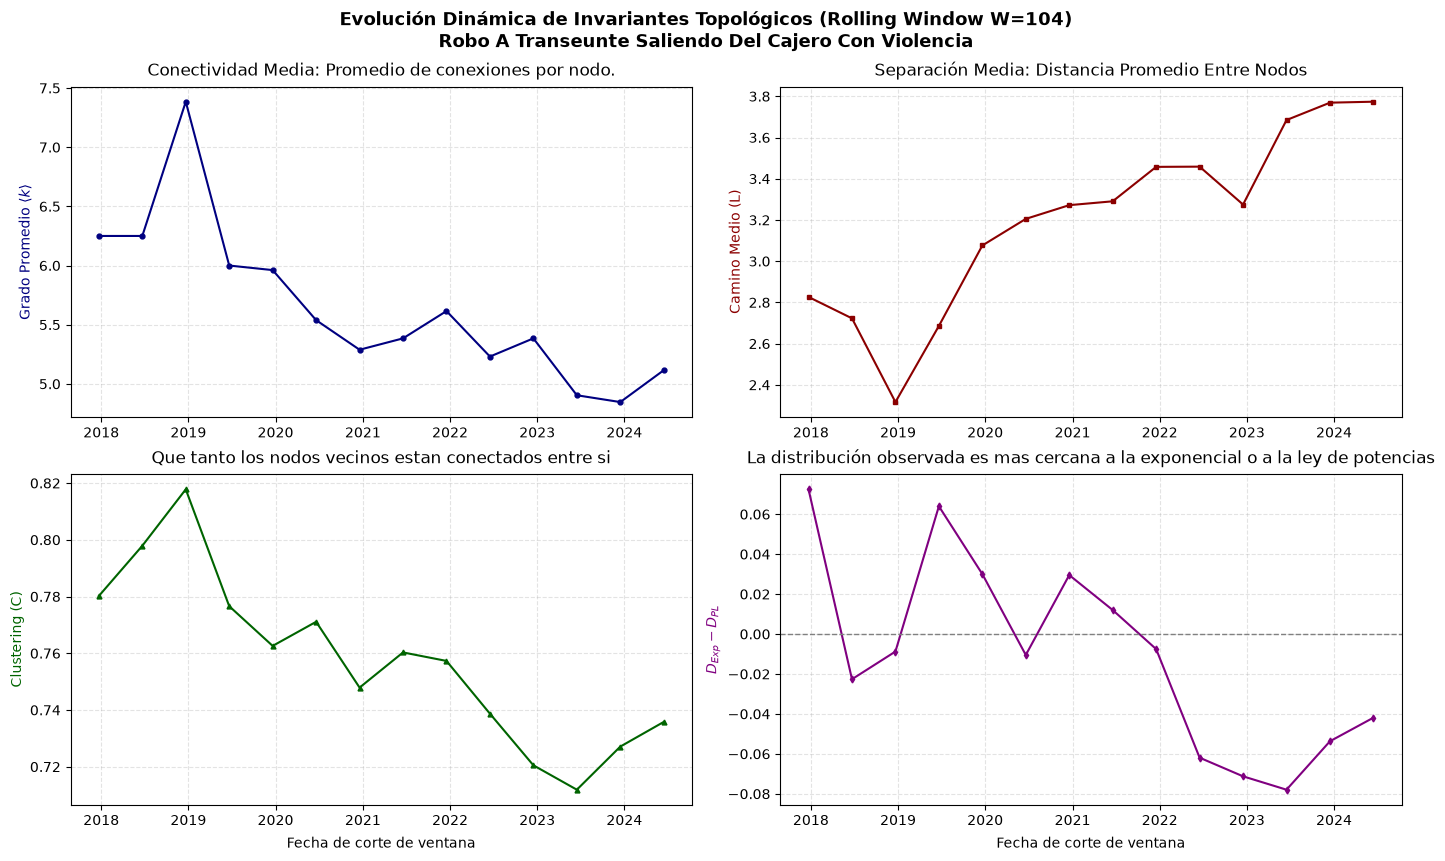

In [16]:
# [VISUALIZACIÓN] Evolución temporal con espaciado vertical corregido
# INPUT:  df_rolling_metrics (pd.DataFrame), TARGET_CRIME (str)
# OUTPUT: None (figura 2x2)
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

# Usamos constrained_layout=True en lugar de tight_layout para evitar colisiones entre títulos y ticks
fig, axes = plt.subplots(
    2, 2, figsize=(14, 8.5), dpi=100, constrained_layout=True
)

fechas = pd.to_datetime(df_rolling_metrics["fecha_corte"])

# 1. Conectividad: Grado Promedio
axes[0, 0].plot(
    fechas,
    df_rolling_metrics["grado_promedio"],
    "o-",
    color="navy",
    markersize=3.5,
)
axes[0, 0].set_ylabel(r"Grado Promedio $\langle k \rangle$", color="navy")
axes[0, 0].grid(True, linestyle="--", alpha=0.35)
axes[0, 0].set_title("Conectividad Media: Promedio de conexiones por nodo.", pad=8)

# 2. Separación Geodésica: Camino Medio
axes[0, 1].plot(
    fechas,
    df_rolling_metrics["camino_medio"],
    "s-",
    color="darkred",
    markersize=3.5,
)
axes[0, 1].set_ylabel("Camino Medio (L)", color="darkred")
axes[0, 1].grid(True, linestyle="--", alpha=0.35)
axes[0, 1].set_title("Separación Media: Distancia Promedio Entre Nodos", pad=8)

# 3. Modularidad Local: Coeficiente de Agrupamiento
axes[1, 0].plot(
    fechas,
    df_rolling_metrics["clustering"],
    "^-",
    color="darkgreen",
    markersize=3.5,
)
axes[1, 0].set_ylabel("Clustering (C)", color="darkgreen")
axes[1, 0].set_xlabel("Fecha de corte de ventana", labelpad=6)
axes[1, 0].grid(True, linestyle="--", alpha=0.35)
axes[1, 0].set_title("Que tanto los nodos vecinos estan conectados entre si", pad=8)

# 4. Régimen Dinámico: Brecha de Distancias Euclidianas
brecha = df_rolling_metrics["dist_eucl_exp"] - df_rolling_metrics["dist_eucl_pl"]
axes[1, 1].plot(fechas, brecha, "d-", color="purple", markersize=3.5)
axes[1, 1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1, 1].set_ylabel(r"$D_{Exp} - D_{PL}$", color="purple")
axes[1, 1].set_xlabel("Fecha de corte de ventana", labelpad=6)
axes[1, 1].grid(True, linestyle="--", alpha=0.35)
axes[1, 1].set_title("La distribución observada es mas cercana a la exponencial o a la ley de potencias", pad=8)

# Formateo explícito de fechas para cada uno de los 4 ejes
locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
formatter = mdates.ConciseDateFormatter(locator)

for ax in axes.flat:
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(formatter)
    # Forzar que se muestren las marcas de fechas en todos los plots sin solaparse
    ax.tick_params(axis="x", labelbottom=True, rotation=0)

fig.suptitle(
    f"Evolución Dinámica de Invariantes Topológicos (Rolling Window W={WINDOW_SIZE})\n"
    f"{TARGET_CRIME.title()}",
    fontsize=13,
    fontweight="bold",
)

plt.show()

# End Rolling Windows

<details>
<summary><b>Ejecución: Construcción del Grafo de Visibilidad Global [DEPRECATED]</b></summary>

<br>

Aplica `build_natural_visibility_graph` sobre la serie completa indexada `df_nodes` para generar la red compleja `visibility_graph` correspondiente a todo el periodo de estudio.

#### Flujo de ejecución
1. **Construcción:** Mapeo de pendientes geométricas entre todas las observaciones de `df_nodes`.
2. **Validación:** Comprobación del orden $\vert{}V\vert{}$ y tamaño $\vert{}E\vert{}$ del grafo consolidado.

#### Variables generadas
* **`visibility_graph`** (`nx.Graph`): Red de visibilidad natural de todo el periodo histórico.

</details>

In [26]:
# [EJECUCIÓN] Construcción del grafo de visibilidad global
# INPUT:  df_nodes (pd.DataFrame)
# OUTPUT: visibility_graph (nx.Graph)

try:
    # 1. Construcción del grafo sobre la serie completa
    visibility_graph = build_natural_visibility_graph(df_nodes)

    # 2. Verificación topológica de la red resultante
    logger.info(f"Total de nodos (|V|): {visibility_graph.number_of_nodes()}")
    logger.info(f"Total de aristas (|E|): {visibility_graph.number_of_edges()}")

except KeyError as err:
    logger.error(f"Error en columna requerida del DataFrame: {err}")
except Exception as err:
    logger.error(f"Fallo en la construcción del grafo global: {err}")

2026-10-06 14:41:59,196 - [build_natural_visibility_graph] - INFO - Construyendo Grafo de Visibilidad Natural
2026-10-06 14:41:59,257 - [build_natural_visibility_graph] - INFO - EXITO. Grafo generado (|V|=443, |E|=1356).
2026-10-06 14:41:59,257 - [<module>] - INFO - Total de nodos (|V|): 443
2026-10-06 14:41:59,258 - [<module>] - INFO - Total de aristas (|E|): 1356


# Analisis de un solo grafo

<details>
<summary><b>Ejecución: Selección y Extracción de Subgrafo por Índice de Ventana</b></summary>

<br>

Valida los límites dimensionales de `rolling_graphs`, extrae la instancia individual `nx.Graph` correspondiente a `SELECTED_WINDOW_IDX` y reasigna el objeto a `visibility_graph` para su inspección con las herramientas de análisis estático.

#### Variables de entrada
* **`rolling_graphs`** (`list[dict]`): Secuencia de ventanas temporales generadas.
* **`SELECTED_WINDOW_IDX`** (`int`): Posición ordinal de la ventana objetivo.

#### Variables generadas
* **`visibility_graph`** (`nx.Graph`): Subgrafo de visibilidad natural de la ventana elegida.

</details>

In [27]:
print(len(rolling_graphs))

14


In [28]:
# [EJECUCIÓN] Extracción segura de subgrafo individual desde rolling_graphs
# INPUT:  rolling_graphs (list[dict]), SELECTED_WINDOW_IDX (int)
# OUTPUT: visibility_graph (nx.Graph)

SELECTED_WINDOW_IDX = 25

try:
    total_ventanas = len(rolling_graphs)
    logger.info(
        f"Total de ventanas disponibles en rolling_graphs: {total_ventanas} (indices válidos: 0 a {total_ventanas - 1})"
    )

    if total_ventanas == 0:
        raise ValueError("La lista 'rolling_graphs' está vacía.")

    # Validación estricta de límites de indexación
    if not (0 <= SELECTED_WINDOW_IDX < total_ventanas):
        raise IndexError(
            f"SELECTED_WINDOW_IDX={SELECTED_WINDOW_IDX} fuera de rango. "
            f"Debe estar entre 0 y {total_ventanas - 1}."
        )

    # Extracción del grafo y metadatos asociados
    selected_window = rolling_graphs[SELECTED_WINDOW_IDX]
    visibility_graph = selected_window["graph"]

    f_inicio = selected_window["start_date"].strftime("%Y-%m-%d")
    f_fin = selected_window["end_date"].strftime("%Y-%m-%d")

    logger.info(
        f"Ventana [{SELECTED_WINDOW_IDX}] extraída exitosamente: "
        f"{f_inicio} a {f_fin} | "
        f"|V|={visibility_graph.number_of_nodes()} nodos, |E|={visibility_graph.number_of_edges()} aristas"
    )
    logger.info("EXITO.")

except (IndexError, ValueError) as err:
    logger.error(f"Error de validación en índice de ventana: {err}")
    logger.info("FALLO.")
except Exception as err:
    logger.error(f"Fallo inesperado al extraer el grafo de la ventana: {err}")
    logger.info("FALLO.")

2026-10-06 14:42:06,005 - [<module>] - INFO - Total de ventanas disponibles en rolling_graphs: 14 (indices válidos: 0 a 13)
2026-10-06 14:42:06,006 - [<module>] - ERROR - Error de validación en índice de ventana: SELECTED_WINDOW_IDX=25 fuera de rango. Debe estar entre 0 y 13.
2026-10-06 14:42:06,006 - [<module>] - INFO - FALLO.


<details>
<summary><b>Visualización: Histograma</b></summary>

<br>

Genera el gráfico interactivo de barras y marcadores discretos extrayendo la topología y atributos temporales almacenados directamente en los nodos del grafo de visibilidad (`nx.Graph`).

#### Parámetros
* **`graph`** (`nx.Graph`): Red compleja con atributos `fecha_hecho` y `cantidad` en cada nodo.
* **`crime_name`** (`str`): Etiqueta del delito para el título descriptivo.

#### Retorno
* **`go.Figure`**: Objeto gráfico interactivo de Plotly renderizado.

</details>

In [29]:
# [HELPERS] Histograma
# INPUT:  graph (nx.Graph), crime_name (str)
# OUTPUT: go.Figure

def plot_weekly_network_nodes(graph: nx.Graph, crime_name: str) -> go.Figure:
    """Renderiza el histograma semanal y la asignación de nodos leyendo desde el grafo."""
    logger.info("Extrayendo atributos de nodos para renderizado")
    if graph.number_of_nodes() == 0:
        logger.warning("El grafo recibido no contiene nodos.")
        return go.Figure()

    # 1. Extracción ordenada de atributos desde los nodos del grafo
    nodes = sorted(graph.nodes())
    fechas = [graph.nodes[n]["fecha_hecho"] for n in nodes]
    cantidades = [graph.nodes[n]["cantidad"] for n in nodes]

    max_val = max(cantidades) if cantidades else 0
    offset = max_val * 0.05 if max_val > 0 else 1

    fig = go.Figure()

    # 2. Barras de delitos por semana
    fig.add_trace(
        go.Bar(
            x=fechas,
            y=cantidades,
            marker=dict(color="white", line=dict(color="black", width=1)),
            name="Delitos",
        )
    )

    # 3. Marcadores de nodos sobre cada barra
    y_markers = [val + offset for val in cantidades]
    text_labels = [str(n) for n in nodes]

    fig.add_trace(
        go.Scatter(
            x=fechas,
            y=y_markers,
            mode="markers+text",
            marker=dict(
                symbol="circle",
                color="white",
                size=14,
                line=dict(color="black", width=1),
            ),
            text=text_labels,
            textfont=dict(color="black", size=8),
            textposition="middle center",
            name="Nodos",
        )
    )

    # 4. Configuración de títulos y ejes
    formatted_crime = str(crime_name).title()
    min_date = min(fechas)
    max_date = max(fechas)

    title_str = (
        f"Asignación de Nodos en la Serie Temporal Semanal de<br><b>{formatted_crime}</b><br>"
        f"<sub>Periodo: {min_date.strftime('%Y-%m-%d')} a {max_date.strftime('%Y-%m-%d')}</sub>"
    )

    # Etiquetas visibles en el eje X (cada 16 semanas)
    visible_ticks = fechas[::16]

    fig.update_layout(
        title=dict(
            text=title_str,
            x=0.5,
            xanchor="center",
            font=dict(size=16, color="black"),
        ),
        width=1300,
        height=750,
        plot_bgcolor="white",
        paper_bgcolor="white",
        bargap=0.1,
        margin=dict(l=70, r=50, t=110, b=100),
        showlegend=False,
        xaxis=dict(
            title="Inicio de Semana (Bloques de 168h)",
            color="black",
            showline=True,
            linecolor="black",
            linewidth=1.5,
            tickangle=45,
            tickmode="array",
            tickvals=visible_ticks,
            tickformat="%Y-%m-%d",
        ),
        yaxis=dict(
            title="Cantidad de delitos",
            color="black",
            showline=True,
            linecolor="black",
            linewidth=1.5,
            showgrid=True,
            gridcolor="lightgrey",
            gridwidth=0.2,
            griddash="dash",
            range=[0, max_val + (offset * 3)],
        ),
    )

    logger.info("Exito.")
    return fig

<details>
<summary><b>Ejecución: Histograma</b></summary>

<br>

Invoca la función de renderizado `plot_weekly_network_nodes` pasando como origen de datos `visibility_graph` y despliega la figura interactiva en el notebook.

#### Variables de entrada
* **`visibility_graph`** (`nx.Graph`): Red compleja generada previamente.
* **`TARGET_CRIME`** (`str`): Constante global del delito analizado.

</details>

In [30]:
# [EJECUCIÓN] Renderizado gráfico de la red
# INPUT:  visibility_graph (nx.Graph), TARGET_CRIME (str)
# OUTPUT: None (despliegue en output)

try:
    fig = plot_weekly_network_nodes(visibility_graph, TARGET_CRIME)
    fig.show()
except Exception as err:
    logger.error(f"Error al renderizar el gráfico: {err}")

2026-10-06 14:42:12,834 - [plot_weekly_network_nodes] - INFO - Extrayendo atributos de nodos para renderizado
2026-10-06 14:42:12,980 - [plot_weekly_network_nodes] - INFO - Exito.


<details>
<summary><b>Visualización: Red de Visibilidad Natural (NVG)</b></summary>

<br>

Renderiza la serie temporal discreta junto con la topología de la Red de Visibilidad Natural (NVG), trazando las aristas entre las cúspides de las observaciones y superponiendo los identificadores de cada nodo.

#### Parámetros
* **`graph`** (`nx.Graph`): Red compleja con coordenadas y atributos temporales (`fecha_hecho`, `cantidad`).
* **`crime_name`** (`str`, opcional): Nombre del delito para la cabecera del gráfico.

#### Retorno
* **`go.Figure`**: Figura interactiva de Plotly con las 4 trazas superpuestas (barras, aristas de visibilidad, cúspides y etiquetas de nodo).

</details>

In [31]:
# [HELPERS] Visualización completa de la red NVG
# INPUT:  graph (nx.Graph), crime_name (str)
# OUTPUT: go.Figure

def plot_visibility_graph_from_network(
    graph: nx.Graph, crime_name: str = ""
) -> go.Figure:
    """Renderiza la serie temporal, aristas de visibilidad y nodos usando únicamente el grafo."""
    logger.info("Extrayendo topología y coordenadas de la red NVG")
    if graph.number_of_nodes() == 0:
        logger.warning("El grafo recibido no contiene nodos.")
        return go.Figure()

    # 1. Coordenadas de los nodos
    nodes = sorted(graph.nodes())
    x_bars = [graph.nodes[i]["fecha_hecho"] for i in nodes]
    y_bars = [graph.nodes[i]["cantidad"] for i in nodes]

    max_val = max(y_bars) if y_bars else 0
    offset = max_val * 0.05 if max_val > 0 else 1

    # 2. Segmentos de aristas de visibilidad (separados por None para trazo continuo)
    edge_x = []
    edge_y = []
    for u, v in graph.edges():
        edge_x.extend([graph.nodes[u]["fecha_hecho"], graph.nodes[v]["fecha_hecho"], None])
        edge_y.extend([graph.nodes[u]["cantidad"], graph.nodes[v]["cantidad"], None])

    fig = go.Figure()

    # Traza 1: Barras de la serie temporal
    fig.add_trace(
        go.Bar(
            x=x_bars,
            y=y_bars,
            marker=dict(color="white", line=dict(color="black", width=1)),
            name="Serie Temporal",
        )
    )

    # Traza 2: Líneas de visibilidad (aristas de la red)
    fig.add_trace(
        go.Scatter(
            x=edge_x,
            y=edge_y,
            mode="lines",
            line=dict(color="red", width=0.8),
            hoverinfo="none",
            name="Visibilidad",
        )
    )

    # Traza 3: Marcadores en la cúspide
    fig.add_trace(
        go.Scatter(
            x=x_bars,
            y=y_bars,
            mode="markers",
            marker=dict(size=4, color="black"),
            hoverinfo="skip",
            name="Cúspides",
        )
    )

    # Traza 4: Nodos numerados sobre las barras
    fig.add_trace(
        go.Scatter(
            x=x_bars,
            y=[y + offset for y in y_bars],
            mode="markers+text",
            marker=dict(
                symbol="circle",
                color="white",
                size=14,
                line=dict(color="black", width=1),
            ),
            text=[str(i) for i in nodes],
            textfont=dict(color="black", size=8),
            textposition="middle center",
            name="Nodos",
        )
    )

    # Configuración de layout
    title_text = "Red de Visibilidad Natural (NVG)"
    if crime_name:
        title_text += f"<br><b>{crime_name.title()}</b>"

    visible_ticks = x_bars[::16]

    fig.update_layout(
        title=dict(
            text=title_text,
            x=0.5,
            xanchor="center",
            font=dict(size=16, color="black"),
        ),
        width=1300,
        height=750,
        plot_bgcolor="white",
        paper_bgcolor="white",
        bargap=0.1,
        margin=dict(l=70, r=50, t=110, b=100),
        showlegend=False,
        xaxis=dict(
            title="Inicio de Semana (Bloques de 168h)",
            color="black",
            showline=True,
            linecolor="black",
            linewidth=1.5,
            tickangle=45,
            tickmode="array",
            tickvals=visible_ticks,
            tickformat="%Y-%m-%d",
        ),
        yaxis=dict(
            title="Cantidad de delitos",
            color="black",
            showline=True,
            linecolor="black",
            linewidth=1.5,
            showgrid=True,
            gridcolor="lightgrey",
            gridwidth=0.2,
            griddash="dash",
            range=[0, max_val + (offset * 3)],
        ),
    )

    logger.info("Exito.")
    return fig

<details>
<summary><b>Ejecución: Visualización del Grafo de Visibilidad Natural</b></summary>

<br>

Invoca `plot_visibility_graph_from_network` sobre el grafo compilado `visibility_graph` para proyectar las interconexiones de visibilidad sobre la serie cronológica.

#### Variables de entrada
* **`visibility_graph`** (`nx.Graph`): Red compleja generada con aristas y atributos.
* **`TARGET_CRIME`** (`str`): Constante global con el nombre del delito en estudio.

</details>

In [32]:
# [EJECUCIÓN] Renderizado del Grafo de Visibilidad Natural (NVG)
# INPUT:  visibility_graph (nx.Graph), TARGET_CRIME (str)
# OUTPUT: None (despliegue en output)

try:
    fig_nvg = plot_visibility_graph_from_network(visibility_graph, TARGET_CRIME)
    fig_nvg.show()
except Exception as err:
    logger.error(f"Error al renderizar el grafo de visibilidad: {err}")

2026-10-06 14:42:18,698 - [plot_visibility_graph_from_network] - INFO - Extrayendo topología y coordenadas de la red NVG
2026-10-06 14:42:18,758 - [plot_visibility_graph_from_network] - INFO - Exito.


<details>
<summary><b>Stats: Métricas Topológicas Globales</b></summary>

<br>

Calcula las propiedades estructurales y de distancia geodésica global del grafo de visibilidad natural, identificando las rutas críticas correspondientes al diámetro y radio de la red.

#### Parámetros
* **`grafo`** (`nx.Graph`): Grafo de visibilidad construido.

#### Retorno
* **`dict`**: Diccionario con métricas escalares y subestructuras:
  * `densidad_empirica`: Proporción de aristas existentes respecto al total teórico posible.
  * `radio` y `diametro`: Excentricidad mínima y máxima de la red conexa.
  * `centro`: Conjunto de nodos cuya excentricidad iguala al radio.
  * `nodos_diametro` / `aristas_diametro`: Ruta geodésica de longitud máxima.
  * `nodos_radio` / `aristas_radio`: Ruta geodésica representativa desde el centro.

</details>

In [33]:
# [STATS] Métricas topológicas globales de la red
# INPUT:  grafo (nx.Graph)
# OUTPUT: dict

def compute_graph_metrics(grafo: nx.Graph) -> dict:
    """Calcula densidad, radio, diámetro, centro y rutas geodésicas del grafo."""
    logger.info("Calculando métricas topológicas globales")
    densidad_empirica = nx.density(grafo)

    radio, diametro, centro = None, None, []
    aristas_diametro, aristas_radio = [], []
    nodos_diametro, nodos_radio = [], []

    if not nx.is_connected(grafo):
        logger.warning("El grafo no es conexo. Métricas basadas en distancias no aplican.")
        return {
            "densidad_empirica": densidad_empirica,
            "radio": radio,
            "diametro": diametro,
            "centro": centro,
            "nodos_diametro": nodos_diametro,
            "aristas_diametro": aristas_diametro,
            "nodos_radio": nodos_radio,
            "aristas_radio": aristas_radio,
        }

    radio = nx.radius(grafo)
    diametro = nx.diameter(grafo)
    centro = nx.center(grafo)

    path_lengths = dict(nx.shortest_path_length(grafo))

    # Identificación del camino diametral
    n1_diam, n2_diam = None, None
    for u in grafo.nodes():
        for v in grafo.nodes():
            if path_lengths[u][v] == diametro:
                n1_diam, n2_diam = u, v
                break
        if n1_diam is not None:
            break

    if n1_diam is not None:
        nodos_diametro = nx.shortest_path(grafo, source=n1_diam, target=n2_diam)
        aristas_diametro = list(zip(nodos_diametro, nodos_diametro[1:]))

    # Identificación del camino radial desde el centro
    if centro:
        nodo_centro = centro[0]
        for target_node in grafo.nodes():
            if path_lengths[nodo_centro][target_node] == radio:
                nodos_radio = nx.shortest_path(
                    grafo, source=nodo_centro, target=target_node
                )
                aristas_radio = list(zip(nodos_radio, nodos_radio[1:]))
                break

    logger.info("EXITO.")
    return {
        "densidad_empirica": densidad_empirica,
        "radio": radio,
        "diametro": diametro,
        "centro": centro,
        "nodos_diametro": nodos_diametro,
        "aristas_diametro": aristas_diametro,
        "nodos_radio": nodos_radio,
        "aristas_radio": aristas_radio,
    }

<details>
<summary><b>Ejecución: Extracción de métricas topológicas</b></summary>

<br>

Ejecuta el cómputo de propiedades estructurales sobre `visibility_graph` y reporta en consola los valores escalares calculados.

#### Variables generadas
* **`topologia_global`** (`dict`): Diccionario con los parámetros calculados y rutas geodésicas.

</details>

In [34]:
# [EJECUCIÓN] Extracción de métricas topológicas globales
# INPUT:  visibility_graph (nx.Graph)
# OUTPUT: topologia_global (dict)

try:
    graph_metrics = compute_graph_metrics(visibility_graph)

    logger.info(f"Densidad empírica: {graph_metrics['densidad_empirica']:.6f}")
    logger.info(f"Radio: {graph_metrics['radio']}")
    logger.info(f"Diámetro: {graph_metrics['diametro']}")
    logger.info(f"Centro: {graph_metrics['centro']}")
    logger.info(f"Nodos en camino diametral: {graph_metrics['nodos_diametro']}")
    logger.info(f"Nodos en camino radial: {graph_metrics['nodos_radio']}")
except Exception as err:
    logger.error(f"Fallo al calcular métricas topológicas: {err}")

2026-10-06 14:42:22,621 - [compute_graph_metrics] - INFO - Calculando métricas topológicas globales
2026-10-06 14:42:23,024 - [compute_graph_metrics] - INFO - EXITO.
2026-10-06 14:42:23,027 - [<module>] - INFO - Densidad empírica: 0.013850
2026-10-06 14:42:23,027 - [<module>] - INFO - Radio: 6
2026-10-06 14:42:23,028 - [<module>] - INFO - Diámetro: 11
2026-10-06 14:42:23,028 - [<module>] - INFO - Centro: [152, 154, 160, 171, 177, 191]
2026-10-06 14:42:23,029 - [<module>] - INFO - Nodos en camino diametral: [7, 6, 5, 17, 49, 152, 191, 261, 275, 280, 292, 294]
2026-10-06 14:42:23,030 - [<module>] - INFO - Nodos en camino radial: [152, 191, 261, 275, 280, 292, 294]


<details>
<summary><b>Visualización: Métricas del grafo</b></summary>

<br>

Renderiza la topología del grafo en el espacio bidimensional mediante el algoritmo de fuerzas `spring_layout` de NetworkX y Matplotlib, resaltando las subestructuras críticas del diámetro (rojo), radio (verde) y centro (amarillo).

#### Parámetros
* **`grafo`** (`nx.Graph`): Red compleja a graficar con atributos de fecha en nodos.
* **`metricas`** (`dict`): Diccionario de métricas globales precalculadas (`densidad_empirica`, `centro`, rutas diametrales y radiales).
* **`crime_name`** (`str`): Delito analizado para el encabezado del lienzo.

#### Retorno
* **`None`**: Despliegue directo del gráfico en el frontend de Matplotlib.

</details>

In [35]:
# [HELPERS] Visualización métricas del grafo
# INPUT:  grafo (nx.Graph), metricas (dict), crime_name (str)
# OUTPUT: None

def plot_network(grafo: nx.Graph, metricas: dict, crime_name: str) -> None:
    """Renderiza la red de visibilidad estática usando Matplotlib con métricas precalculadas."""
    logger.info("Preparando renderizado del grafo topológico")
    if grafo.number_of_nodes() == 0:
        logger.warning("El grafo recibido está vacío.")
        return

    # 1. Rango temporal para el título
    fechas = [
        pd.to_datetime(data["fecha_hecho"])
        for _, data in grafo.nodes(data=True)
        if "fecha_hecho" in data
    ]
    rango_fechas = (
        f"({min(fechas).strftime('%Y-%m-%d')} – {max(fechas).strftime('%Y-%m-%d')})"
        if fechas
        else ""
    )
    titulo_grafico = (
        f"Red de Visibilidad Semanal con Métricas Clave\n"
        f"{crime_name.title()}\n{rango_fechas}"
    )

    # 2. Lienzo y disposición espacial
    fig, ax = plt.subplots(figsize=(15, 8))
    pos = nx.spring_layout(grafo, seed=42)

    # 3. Capas base
    nx.draw_networkx_edges(
        grafo, pos, edge_color="lightgray", width=1.0, alpha=0.6, ax=ax
    )
    nx.draw_networkx_nodes(
        grafo,
        pos,
        node_color="white",
        node_size=180,
        edgecolors="black",
        linewidths=0.6,
        ax=ax,
    )

    # 4. Capas para métricas extremas (diámetro, radio, centro)
    if metricas.get("aristas_diametro"):
        nx.draw_networkx_edges(
            grafo,
            pos,
            edgelist=metricas["aristas_diametro"],
            edge_color="red",
            width=2.5,
            ax=ax,
        )
    if metricas.get("aristas_radio"):
        nx.draw_networkx_edges(
            grafo,
            pos,
            edgelist=metricas["aristas_radio"],
            edge_color="green",
            width=2.5,
            ax=ax,
        )
    if metricas.get("centro"):
        nx.draw_networkx_nodes(
            grafo,
            pos,
            nodelist=metricas["centro"],
            node_color="yellow",
            node_size=220,
            edgecolors="black",
            ax=ax,
        )

    nx.draw_networkx_labels(grafo, pos, font_size=5.5, font_weight="bold", ax=ax)

    # 5. Construcción de leyenda
    elementos_leyenda = [
        Line2D(
            [0],
            [0],
            color="w",
            label=f"Densidad Empírica: {metricas.get('densidad_empirica', 0):.4f}",
        )
    ]
    if metricas.get("centro"):
        elementos_leyenda.append(
            Line2D(
                [0],
                [0],
                marker="o",
                color="w",
                label=f"Centro: {metricas['centro']}",
                markerfacecolor="yellow",
                markersize=10,
                markeredgecolor="black",
            )
        )
    if metricas.get("diametro") is not None:
        elementos_leyenda.append(
            Line2D(
                [0],
                [0],
                color="red",
                lw=3,
                label=f"Diámetro: {metricas['diametro']}",
            )
        )
    if metricas.get("radio") is not None:
        elementos_leyenda.append(
            Line2D(
                [0],
                [0],
                color="green",
                lw=3,
                label=f"Radio: {metricas['radio']}",
            )
        )

    ax.legend(
        handles=elementos_leyenda,
        loc="best",
        facecolor="white",
        framealpha=0.8,
        fontsize=10,
    )

    plt.title(titulo_grafico, fontsize=16, pad=15)
    plt.axis("off")
    plt.show()
    logger.info("Exito.")

<details>
<summary><b>Ejecución: Visualización de la Red de Visibilidad Topológica</b></summary>

<br>

Ejecuta el trazado de la red global utilizando las métricas contenidas en `topologia_global` sobre `visibility_graph`.

#### Variables de entrada
* **`visibility_graph`** (`nx.Graph`): Red compleja del delito seleccionado.
* **`topologia_global`** (`dict`): Diccionario con rutas geodésicas y métricas de centralidad calculadas.
* **`TARGET_CRIME`** (`str`): Constante del delito analizado.

</details>

2026-10-06 14:42:27,218 - [plot_network] - INFO - Preparando renderizado del grafo topológico


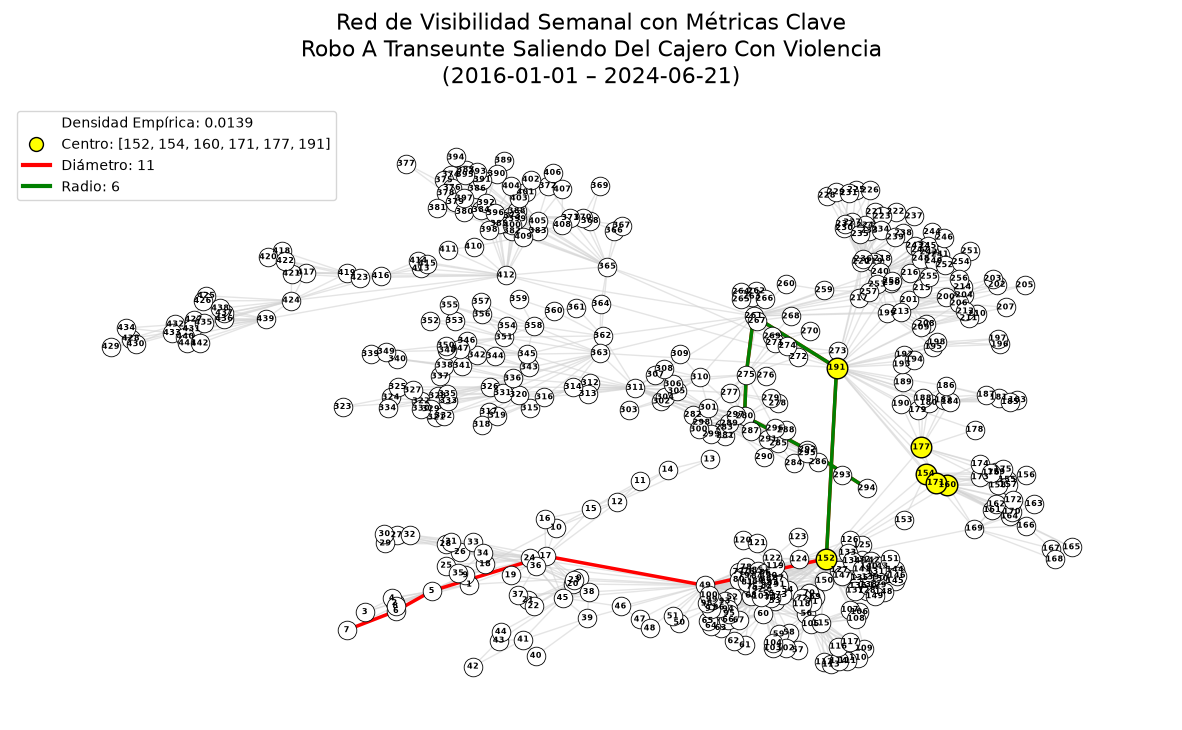

2026-10-06 14:42:29,069 - [plot_network] - INFO - Exito.


In [36]:
# [EJECUCIÓN] Renderizado de red topológica con métricas
# INPUT:  visibility_graph (nx.Graph), graph_metrics (dict), TARGET_CRIME (str)
# OUTPUT: None (despliegue en output)

try:
    plot_network(visibility_graph, graph_metrics, TARGET_CRIME)
except Exception as err:
    logger.error(f"Fallo al renderizar el gráfico topológico: {err}")

<details>
<summary><b>Stats: Métricas y Centralidades por Nodo</b></summary>

<br>

Calcula las métricas estructurales locales para cada vértice de la red (grado, intermediación, cercanía, agrupamiento y excentricidad) integrándolas con los atributos temporales y de frecuencia de eventos.

#### Parámetros
* **`grafo`** (`nx.Graph`): Red compleja con atributos `fecha_hecho` y `cantidad` asignados a cada nodo.

#### Retorno
* **`pd.DataFrame`**: Tabla consolidada con las métricas locales indexadas por nodo.

</details>

In [37]:
# [HELPERS] Métricas y centralidades por nodo
# INPUT:  grafo (nx.Graph)
# OUTPUT: pd.DataFrame

def compute_node_metrics(grafo: nx.Graph) -> pd.DataFrame:
    """Calcula métricas topológicas locales por nodo y devuelve un DataFrame consolidado."""
    logger.info("Calculando métricas y centralidades por nodo")
    if grafo.number_of_nodes() == 0:
        logger.warning("El grafo recibido no contiene nodos.")
        return pd.DataFrame()

    # 1. Medidas de conectividad y centralidad
    grados = dict(grafo.degree())
    intermediacion = nx.betweenness_centrality(grafo)
    cercania = nx.closeness_centrality(grafo)
    agrupamiento = nx.clustering(grafo)

    if nx.is_connected(grafo):
        excentricidad = nx.eccentricity(grafo)
    else:
        excentricidad = {n: "N/A" for n in grafo.nodes()}

    # 2. Construcción tabular con atributos del nodo
    registros = []
    for nodo, datos in sorted(grafo.nodes(data=True)):
        fecha_dt = pd.to_datetime(datos.get("fecha_hecho", pd.NaT))
        fecha_str = fecha_dt.strftime("%Y-%m-%d") if pd.notna(fecha_dt) else "N/A"

        registros.append(
            {
                "Nodo": nodo,
                "Inicio de Semana(fecha_hecho)": fecha_str,
                "Delitos(cantidad)": datos.get("cantidad", 0),
                "Grado (Conexiones)": grados.get(nodo, 0),
                "Intermediación": round(intermediacion.get(nodo, 0.0), 4),
                "Cercanía": round(cercania.get(nodo, 0.0), 4),
                "Agrupamiento": round(agrupamiento.get(nodo, 0.0), 4),
                "Excentricidad": excentricidad.get(nodo),
            }
        )

    logger.info(f"Exito. Métricas generadas para {len(registros)} nodos.")
    return pd.DataFrame(registros)

<details>
<summary><b>Ejecución: Cómputo de métricas por nodo</b></summary>

<br>

Ejecuta `compute_node_metrics` sobre el grafo compilado `visibility_graph` para construir la tabla de propiedades nodales `df_node_metrics`.

#### Variables generadas
* **`df_node_metrics`** (`pd.DataFrame`): Conjunto estructurado con las métricas locales de cada nodo temporal.

</details>

In [38]:
# [EJECUCIÓN] Cómputo de métricas por nodo
# INPUT:  visibility_graph (nx.Graph)
# OUTPUT: df_node_metrics (pd.DataFrame)

try:
    df_node_metrics = compute_node_metrics(visibility_graph)
    logger.info(f"Dimensiones de df_node_metrics: {df_node_metrics.shape}")
    display(df_node_metrics.head())
except Exception as err:
    logger.error(f"Fallo al calcular las métricas por nodo: {err}")

2026-10-06 14:42:34,563 - [compute_node_metrics] - INFO - Calculando métricas y centralidades por nodo
2026-10-06 14:42:35,197 - [compute_node_metrics] - INFO - Exito. Métricas generadas para 443 nodos.
2026-10-06 14:42:35,200 - [<module>] - INFO - Dimensiones de df_node_metrics: (443, 8)


,Nodo,Inicio de Semana(fecha_hecho),Delitos(cantidad),Grado (Conexiones),Intermediación,Cercanía,Agrupamiento,Excentricidad
0,0,2016-01-01,2.0,3,0.0048,0.2283,0.6667,8
1,1,2016-01-08,2.0,5,0.0058,0.1898,0.5000,9
2,2,2016-01-15,1.0,4,0.0000,0.1600,0.8333,10
3,3,2016-01-22,0.0,3,0.0000,0.1599,1.0000,10
4,4,2016-01-29,0.0,4,0.0000,0.1600,0.8333,10


<details>
<summary><b>Reportes: Resumen Analítico de Métricas Topológicas</b></summary>

<br>

Genera el reporte tabular consolidado del análisis de la red de visibilidad, consumiendo las propiedades globales de `graph_metrics` y las métricas nodales precalculadas en `df_node_metrics`.

#### Parámetros
* **`grafo`** (`nx.Graph`): Red compleja evaluada.
* **`graph_metrics`** (`dict`): Diccionario con métricas globales (diámetro, radio, centro).
* **`df_nodes`** (`pd.DataFrame`): DataFrame con las métricas y centralidades por nodo.

#### Retorno
* **`None`**: Emisión del reporte analítico formateado en consola.

</details>

In [39]:
# [HELPERS] Generación de reporte analítico consolidado
# INPUT:  grafo (nx.Graph), graph_metrics (dict), df_nodes (pd.DataFrame)
# OUTPUT: None (impresión en consola)

def print_network_metrics_summary(
    grafo: nx.Graph, graph_metrics: dict, df_nodes: pd.DataFrame
) -> None:
    """Imprime un reporte analítico exhaustivo consumiendo métricas precalculadas."""
    logger.info("Generando resumen analítico de métricas")
    if grafo.number_of_nodes() == 0 or df_nodes.empty:
        logger.warning("Grafo o DataFrame de métricas vacío.")
        return

    print("======================================================")
    print("   RESUMEN DE MÉTRICAS DE LA RED DE VISIBILIDAD SEMANAL ")
    print("======================================================")

    # 1. Métricas Generales
    print("\n--- 1. MÉTRICAS GENERALES DE LA RED ---")
    print(f"- Número total de Nodos (Semanas): {grafo.number_of_nodes()}")
    print(f"- Número total de Enlaces: {grafo.number_of_edges()}")
    print(f"- Componentes Conectados: {nx.number_connected_components(grafo)}")
    print(f"- Densidad Empírica: {graph_metrics.get('densidad_empirica', 0):.6f}")

    # 2. Métricas de Distancia
    print("\n--- 2. MÉTRICAS DE DISTANCIA ---")
    if nx.is_connected(grafo):
        print(f"- Diámetro de la Red: {graph_metrics.get('diametro')}")
        print(f"- Radio de la Red: {graph_metrics.get('radio')}")
        print(f"- Centro de la Red (Nodos): {graph_metrics.get('centro')}")

        top_centricos = df_nodes.sort_values(
            by=["Excentricidad", "Nodo"], ascending=[True, True]
        ).head(5)
        print("\n  - TOP 5 Nodos con Menor Excentricidad (más céntricos):")
        for _, r in top_centricos.iterrows():
            print(
                f"    - Nodo {r['Nodo']} (Semana {r['Inicio de Semana(fecha_hecho)']}): "
                f"Excentricidad = {r['Excentricidad']}"
            )
    else:
        print(
            "- El grafo no es conexo, no se pueden calcular Diámetro, Radio, Centro ni Excentricidad."
        )

    # 3. Análisis de Nodos Clave
    print("\n--- 3. ANÁLISIS DE NODOS CLAVE ---")
    nodo_pico_row = df_nodes.loc[df_nodes["Delitos(cantidad)"].idxmax()]
    print("\n  - Nodo Pico (Semana con Valor Máximo):")
    print(
        f"    - Nodo {int(nodo_pico_row['Nodo'])} "
        f"(Inicio {nodo_pico_row['Inicio de Semana(fecha_hecho)']}) con "
        f"{nodo_pico_row['Delitos(cantidad)']} delitos"
    )
    print("    - Métricas Específicas del Nodo Pico:")
    print(f"      - Grado (Conexiones): {nodo_pico_row['Grado (Conexiones)']}")
    print(f"      - Excentricidad: {nodo_pico_row['Excentricidad']}")
    print(
        f"      - Centralidad de Intermediación: {nodo_pico_row['Intermediación']:.4f}"
    )
    print(f"      - Centralidad de Cercanía: {nodo_pico_row['Cercanía']:.4f}")
    print(
        f"      - Coeficiente de Agrupamiento: {nodo_pico_row['Agrupamiento']:.4f}"
    )

    centros = graph_metrics.get("centro", [])
    if centros:
        print(f"\n  - Métricas de los Nodos del Centro Geodésico ({centros}):")
        df_centros = df_nodes[df_nodes["Nodo"].isin(centros)]
        for _, r in df_centros.iterrows():
            print(
                f"    - Análisis del Nodo {int(r['Nodo'])} (Semana {r['Inicio de Semana(fecha_hecho)']}):"
            )
            print(f"      - Grado (Conexiones): {r['Grado (Conexiones)']}")
            print(
                f"      - Centralidad de Intermediación: {r['Intermediación']:.4f}"
            )
            print(f"      - Centralidad de Cercanía: {r['Cercanía']:.4f}")
            print(
                f"      - Coeficiente de Agrupamiento: {r['Agrupamiento']:.4f}"
            )

    # 4. TOP 5 Nodos por Métrica
    print("\n--- 4. TOP 5 NODOS POR MÉTRICA ---")

    print("\n  - TOP 5 Nodos con Mayor Grado (más conectados):")
    for _, r in (
        df_nodes.sort_values(by="Grado (Conexiones)", ascending=False)
        .head(5)
        .iterrows()
    ):
        print(
            f"    - Nodo {int(r['Nodo'])} ({r['Inicio de Semana(fecha_hecho)']}): "
            f"{r['Grado (Conexiones)']} conexiones"
        )

    print("\n  - TOP 5 Nodos con Mayor Centralidad de Intermediación (puentes):")
    for _, r in (
        df_nodes.sort_values(by="Intermediación", ascending=False)
        .head(5)
        .iterrows()
    ):
        print(
            f"    - Nodo {int(r['Nodo'])} ({r['Inicio de Semana(fecha_hecho)']}): "
            f"{r['Intermediación']:.4f}"
        )

    print("\n  - TOP 5 Nodos con Mayor Centralidad de Cercanía (mejor acceso):")
    for _, r in (
        df_nodes.sort_values(by="Cercanía", ascending=False).head(5).iterrows()
    ):
        print(
            f"    - Nodo {int(r['Nodo'])} ({r['Inicio de Semana(fecha_hecho)']}): "
            f"{r['Cercanía']:.4f}"
        )

    # 5. Coeficiente de Agrupamiento
    print("\n--- 5. COEFICIENTE DE AGRUPAMIENTO (CLUSTERING) ---")
    print("\n  - Nodos con Mayor Coeficiente (en grupos más densos):")
    for _, r in (
        df_nodes.sort_values(by="Agrupamiento", ascending=False)
        .head(5)
        .iterrows()
    ):
        print(
            f"    - Nodo {int(r['Nodo'])} ({r['Inicio de Semana(fecha_hecho)']}): "
            f"{r['Agrupamiento']:.4f}"
        )

    print("\n  - Nodos con Menor Coeficiente (>0):")
    df_clustering_pos = df_nodes[df_nodes["Agrupamiento"] > 0]
    nodos_menor = (
        df_clustering_pos.sort_values(by="Agrupamiento", ascending=True).head(5)
        if not df_clustering_pos.empty
        else df_nodes.sort_values(by="Agrupamiento", ascending=True).head(5)
    )

    for _, r in nodos_menor.iterrows():
        print(
            f"    - Nodo {int(r['Nodo'])} ({r['Inicio de Semana(fecha_hecho)']}): "
            f"{r['Agrupamiento']:.4f}"
        )

    print("\n======================================================")
    print("     Análisis de Métricas Semanales Finalizado        ")
    print("======================================================")
    logger.info("Exito.")

<details>
<summary><b>Ejecución: Reporte consolidado de métricas de red</b></summary>

<br>

Invoca `print_network_metrics_summary` para formatear y desplegar el diagnóstico estructural completo en stdout sin recalcular métricas costosas.

#### Variables de entrada
* **`visibility_graph`** (`nx.Graph`): Red analizada.
* **`graph_metrics`** (`dict`): Métricas globales precalculadas.
* **`df_node_metrics`** (`pd.DataFrame`): Métricas por nodo precalculadas.

</details>

In [40]:
# [EJECUCIÓN] Reporte consolidado de métricas
# INPUT:  visibility_graph (nx.Graph), graph_metrics (dict), df_node_metrics (pd.DataFrame)
# OUTPUT: None (impresión en stdout)

try:
    print_network_metrics_summary(
        visibility_graph, graph_metrics, df_node_metrics
    )
except Exception as err:
    logger.error(f"Fallo al emitir el resumen analítico: {err}")

2026-10-06 14:42:38,898 - [print_network_metrics_summary] - INFO - Generando resumen analítico de métricas
   RESUMEN DE MÉTRICAS DE LA RED DE VISIBILIDAD SEMANAL 

--- 1. MÉTRICAS GENERALES DE LA RED ---
- Número total de Nodos (Semanas): 443
- Número total de Enlaces: 1356
- Componentes Conectados: 1
- Densidad Empírica: 0.013850

--- 2. MÉTRICAS DE DISTANCIA ---
- Diámetro de la Red: 11
- Radio de la Red: 6
- Centro de la Red (Nodos): [152, 154, 160, 171, 177, 191]

  - TOP 5 Nodos con Menor Excentricidad (más céntricos):
    - Nodo 152 (Semana 2018-11-30): Excentricidad = 6
    - Nodo 154 (Semana 2018-12-14): Excentricidad = 6
    - Nodo 160 (Semana 2019-01-25): Excentricidad = 6
    - Nodo 171 (Semana 2019-04-12): Excentricidad = 6
    - Nodo 177 (Semana 2019-05-24): Excentricidad = 6

--- 3. ANÁLISIS DE NODOS CLAVE ---

  - Nodo Pico (Semana con Valor Máximo):
    - Nodo 152 (Inicio 2018-11-30) con 7.0 delitos
    - Métricas Específicas del Nodo Pico:
      - Grado (Conexiones): 

<details>
<summary><b>Visualización: Distribución de Grados</b></summary>

<br>

Genera el diagrama de barras de la secuencia ordenada de grados (conectividad) de la red, permitiendo evaluar de forma preliminar la heterogeneidad en el número de enlaces y la presencia de hubs temporales.

#### Parámetros
* **`grafo`** (`nx.Graph`): Grafo de visibilidad con atributos temporales en los nodos.
* **`crime_name`** (`str`): Delito analizado para el encabezado del gráfico.

#### Retorno
* **`None`**: Despliegue directo del gráfico en el frontend de Matplotlib.

</details>

In [41]:
# [HELPERS] Visualización de la distribución de grados ordenada
# INPUT:  grafo (nx.Graph), crime_name (str)
# OUTPUT: None

def plot_degree_distribution(grafo: nx.Graph, crime_name: str) -> None:
    """Genera el gráfico de barras de la distribución ordenada de grados."""
    logger.info("Preparando gráfico de distribución de grados")
    if grafo.number_of_nodes() == 0:
        logger.warning("El grafo recibido está vacío.")
        return

    # 1. Grados ordenados descendentemente
    grados_ordenados = sorted((grado for _, grado in grafo.degree()), reverse=True)

    # 2. Rango de fechas para el título
    fechas = [
        pd.to_datetime(data["fecha_hecho"])
        for _, data in grafo.nodes(data=True)
        if "fecha_hecho" in data
    ]
    rango_fechas = (
        f"({min(fechas).strftime('%Y-%m-%d')} – {max(fechas).strftime('%Y-%m-%d')})"
        if fechas
        else "(Periodo Desconocido)"
    )

    titulo = (
        f"Distribución de Grados en la Red de Visibilidad Semanal\n"
        f"{crime_name.title()}\n{rango_fechas}"
    )

    # 3. Lienzo
    fig, ax = plt.subplots(figsize=(8, 5.5), dpi=100)
    fig.patch.set_facecolor("white")
    ax.patch.set_facecolor("white")

    # 4. Barras
    x_pos = np.arange(len(grados_ordenados))
    ax.bar(
        x_pos,
        grados_ordenados,
        color="white",
        edgecolor="black",
        linewidth=1.2,
    )

    # 5. Estilos y formato
    ax.set_title(titulo, fontsize=13, pad=15, color="black")
    ax.set_ylabel("Grado del nodo (Conexiones)", fontsize=11, color="black")
    ax.set_xlabel(
        "Nodos (Semanas) ordenados por conectividad", fontsize=11, color="black"
    )

    gmax = max(grados_ordenados) if grados_ordenados else 0
    ax.set_ylim(0, gmax + max(1, int(gmax * 0.08)))

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("black")
    ax.spines["bottom"].set_color("black")

    ax.tick_params(axis="both", direction="out", colors="black", labelsize=9)
    ax.yaxis.grid(True, linestyle="--", alpha=0.3, color="gray")

    plt.tight_layout()
    plt.show()
    logger.info("Exito.")

<details>
<summary><b>Ejecución: Renderizado de la distribución de conectividad</b></summary>

<br>

Invoca `plot_degree_distribution` para graficar la secuencia decreciente de conexiones sobre `visibility_graph`.

#### Variables de entrada
* **`visibility_graph`** (`nx.Graph`): Red compleja generada.
* **`TARGET_CRIME`** (`str`): Constante global del delito analizado.

</details>

2026-10-06 14:42:44,427 - [plot_degree_distribution] - INFO - Preparando gráfico de distribución de grados


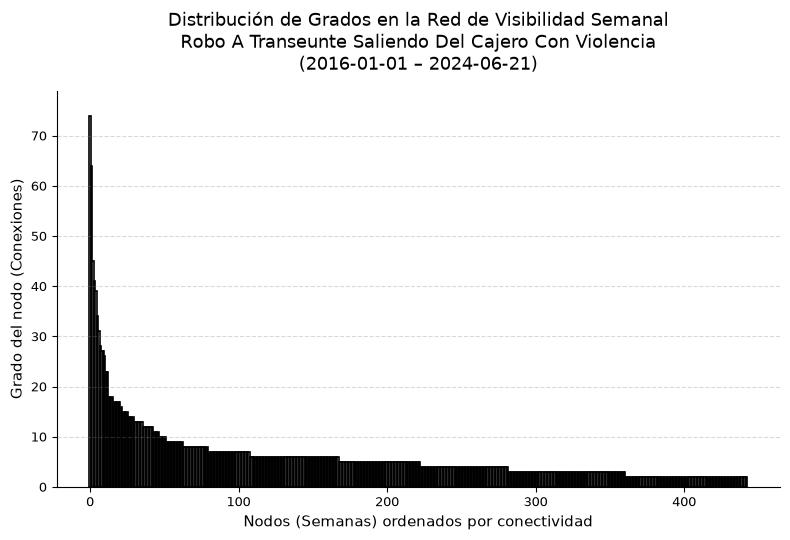

2026-10-06 14:42:44,960 - [plot_degree_distribution] - INFO - Exito.


In [42]:
# [EJECUCIÓN] Renderizado de distribución de grados
# INPUT:  visibility_graph (nx.Graph), TARGET_CRIME (str)
# OUTPUT: None (despliegue en output)

try:
    plot_degree_distribution(visibility_graph, TARGET_CRIME)
except Exception as err:
    logger.error(f"Fallo al graficar la distribución de grados: {err}")

<details>
<summary><b>Análisis Estadístico: Ajuste de Ley de Potencia</b></summary>

<br>

Ajusta el modelo estadístico de Ley de Potencia ($P(k) \sim k^{-\gamma}$) a la distribución empírica de grados mediante el formalismo de Clauset, Shalizi y Newman (CSN) vía la librería `powerlaw`.

#### Métodos y pruebas incluidas
* **Estimación de parámetros:** Cálculo del umbral óptimo $x_{\min}$ y del exponente de escala $\gamma$ ($\alpha$) por máxima verosimilitud.
* **Test de razón de verosimilitud ($R$):** Comparación directa entre la hipótesis de Ley de Potencia frente al modelo alternativo Lognormal.
* **Visualización:** Gráfico en escala logarítmica ($\log$-$\log$) con simulación de dispersión en el exponente $\gamma$.

#### Parámetros
* **`grafo`** (`nx.Graph`): Red compleja evaluada.
* **`crime_name`** (`str`): Delito analizado para el título de la figura.

#### Retorno
* **`None`**: Despliegue directo del gráfico en el frontend de Matplotlib.

</details>

In [43]:
# [HELPERS] Ajuste estadístico y gráfico de Ley de Potencia
# INPUT:  grafo (nx.Graph), crime_name (str)
# OUTPUT: None

def plot_power_law_fit(grafo: nx.Graph, crime_name: str) -> None:
    """Calcula y grafica el ajuste de Ley de Potencia (P(k)) para la red."""
    logger.info("Iniciando ajuste estadístico de Ley de Potencia")
    if grafo.number_of_nodes() == 0:
        logger.warning("El grafo recibido está vacío.")
        return

    # 1. Preparación de grados (filtrar nodos con k = 0)
    data = np.array([d for _, d in grafo.degree() if d > 0])
    if len(data) == 0:
        logger.warning("El grafo no contiene nodos con grado positivo.")
        return

    # 2. Ajuste matemático (Clauset et al.) aislando warnings numéricos de SciPy
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=OptimizeWarning)
        fit = powerlaw.Fit(data, discrete=True, verbose=False)
        R, p_value_PL = fit.distribution_compare(
            "power_law", "lognormal", normalized_ratio=True
        )

    res_log = "Power Law" if R > 0 else "Alternativa"

    sigma_val = fit.power_law.sigma
    xmin_val = fit.power_law.xmin
    gamma_val = fit.power_law.alpha
    nodos_cumplen = np.sum(data >= xmin_val)

    # 3. Rango de fechas para el título
    fechas = [
        pd.to_datetime(d["fecha_hecho"])
        for _, d in grafo.nodes(data=True)
        if "fecha_hecho" in d
    ]
    rango_fechas = (
        f"({min(fechas).strftime('%Y-%m-%d')} – {max(fechas).strftime('%Y-%m-%d')})"
        if fechas
        else "(Periodo Desconocido)"
    )

    titulo = (
        f"Distribución de Grado P(k) y Ajuste de Ley de Potencia (CSN)\n"
        f"Red de Visibilidad Semanal - {crime_name.title()}\n"
        f"{rango_fechas}"
    )

    # 4. Construcción del gráfico
    plt.figure(figsize=(7, 5), dpi=100)

    # Simulación de dispersión de gamma
    x_space = np.linspace(xmin_val, data.max(), 100)
    for s in np.linspace(-2, 2, 50):
        gamma_var = gamma_val + (s * sigma_val)
        y_var = (
            (gamma_var - 1)
            * (xmin_val ** (gamma_var - 1))
            * (x_space**-gamma_var)
        )
        plt.plot(
            x_space,
            y_var,
            color="royalblue",
            alpha=0.15,
            linewidth=0.6,
            zorder=1,
        )

    # Curva empírica y ajuste óptimo
    fit.plot_pdf(
        color="black",
        marker="o",
        linestyle="None",
        markersize=5,
        label="Datos Empíricos",
    )
    fit.power_law.plot_pdf(
        color="red",
        linestyle="--",
        linewidth=2,
        label="Ajuste Óptimo Power Law",
    )

    # 5. Caja de texto estadístico
    texto_stats = (
        r"$\mathbf{Métricas\ del\ Ajuste:}$" + "\n"
        f"Gamma ($\\gamma$): {gamma_val:.4f}\n"
        f"Xmin: {xmin_val:.2f}\n"
        f"Nodos (k >= Xmin): {nodos_cumplen} / {len(data)}\n\n"
        r"$\mathbf{Bondad\ de\ Ajuste:}$" + "\n"
        f"p-value (PL): {p_value_PL:.4f}\n\n"
        r"$\mathbf{Comparación\ (R):}$" + "\n"
        f"R: {R:.4f} ({res_log})"
    )

    plt.text(
        0.05,
        0.05,
        texto_stats,
        transform=plt.gca().transAxes,
        fontsize=8,
        verticalalignment="bottom",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
    )

    plt.title(titulo, fontsize=11, pad=15)
    plt.xlabel("Grado (k)", fontsize=10)
    plt.ylabel("P(k)", fontsize=10)
    plt.xscale("log")
    plt.yscale("log")
    plt.grid(True, which="both", ls="--", alpha=0.3)
    plt.legend(loc="upper right", fontsize=8)

    plt.tight_layout()
    plt.show()
    logger.info("Exito.")

<details>
<summary><b>Ejecución: Estimación y ajuste de Ley de Potencia</b></summary>

<br>

Invoca `plot_power_law_fit` para evaluar si la conectividad de `visibility_graph` exhibe invariancia de escala frente a la alternativa lognormal.

#### Variables de entrada
* **`visibility_graph`** (`nx.Graph`): Red compleja analizada.
* **`TARGET_CRIME`** (`str`): Delito bajo estudio.

</details>

In [ ]:
# [EJECUCIÓN] Ajuste y evaluación de Ley de Potencia
# INPUT:  visibility_graph (nx.Graph), TARGET_CRIME (str)
# OUTPUT: None (despliegue en output)

try:
    plot_power_law_fit(visibility_graph, TARGET_CRIME)
except Exception as err:
    logger.error(f"Fallo en el ajuste de Ley de Potencia: {err}")

<details>
<summary><b>Análisis Estadístico: Comparación Multimodelo y Distancia Euclidiana</b></summary>

<br>

Ajusta y compara de forma multimodelo las distribuciones teóricas alternativas (Ley de Potencia, Log-Normal y Exponencial) sobre el régimen de cola ($k \geq x_{\min}$), evaluando la bondad de ajuste mediante la distancia euclidiana discreta respecto a las frecuencias empíricas.

#### Parámetros
* **`grafo`** (`nx.Graph`): Red compleja evaluada.
* **`crime_name`** (`str`): Delito analizado para el título del gráfico.

#### Retorno
* **`pd.DataFrame`**: Tabla resumen de distancias euclidianas ordenadas descendentemente por proximidad al dato empírico.

</details>

In [44]:
# [HELPERS] Comparación multimodelo y distancia euclidiana
# INPUT:  grafo (nx.Graph), crime_name (str)
# OUTPUT: pd.DataFrame

def plot_model_comparison(grafo: nx.Graph, crime_name: str) -> pd.DataFrame:
    """Compara modelos teóricos frente a la distribución empírica y grafica las curvas."""
    logger.info("Iniciando comparacion multimodelo y calculo de distancias")
    if grafo.number_of_nodes() == 0:
        logger.warning("El grafo recibido está vacío.")
        return pd.DataFrame()

    # 1. Grados positivos
    data = np.array([d for _, d in grafo.degree() if d > 0])
    if len(data) == 0:
        logger.warning("El grafo no contiene nodos con grado positivo.")
        return pd.DataFrame()

    # 2. Ajuste multimodelo aislando warnings de convergencia
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=OptimizeWarning)
        fit = powerlaw.Fit(data, discrete=True, verbose=False)

    xmin_val = fit.xmin

    # 3. Filtrado de cola (k >= xmin) y frecuencias empíricas
    data_xmin = data[data >= xmin_val]
    if len(data_xmin) == 0:
        logger.warning("Muestra insuficiente para k >= xmin.")
        return pd.DataFrame()

    k_eval, counts = np.unique(data_xmin, return_counts=True)
    y_emp_eval = counts / len(data_xmin)

    # 4. Evaluación de funciones de densidad teóricas (PDF)
    y_pl = fit.power_law.pdf(k_eval)
    y_lognorm = fit.lognormal.pdf(k_eval)
    y_exp = fit.exponential.pdf(k_eval)

    # 5. Distancia euclidiana vectorial: ||y_emp - y_teorica||_2
    dist_pl = float(np.linalg.norm(y_emp_eval - y_pl))
    dist_lognorm = float(np.linalg.norm(y_emp_eval - y_lognorm))
    dist_exp = float(np.linalg.norm(y_emp_eval - y_exp))

    df_distancias = pd.DataFrame(
        {
            "Modelo": ["Ley de Potencia", "Log-Normal", "Exponencial"],
            "Distancia Euclidiana": [dist_pl, dist_lognorm, dist_exp],
        }
    ).sort_values(by="Distancia Euclidiana").reset_index(drop=True)

    # 6. Rango temporal para título
    fechas = [
        pd.to_datetime(d["fecha_hecho"])
        for _, d in grafo.nodes(data=True)
        if "fecha_hecho" in d
    ]
    rango_fechas = (
        f"({min(fechas).strftime('%Y-%m-%d')} – {max(fechas).strftime('%Y-%m-%d')})"
        if fechas
        else "(Periodo Desconocido)"
    )

    titulo = (
        f"Comparación de Modelos Teóricos y Distancia Euclidiana\n"
        f"Red de Visibilidad Semanal - {crime_name.title()}\n"
        f"{rango_fechas}"
    )

    # 7. Renderizado en escala log-log
    plt.figure(figsize=(8, 6), dpi=100)
    plt.plot(
        k_eval,
        y_emp_eval,
        "ko",
        label=r"Datos Empíricos ($k \geq x_{min}$)",
        markersize=5,
    )
    plt.plot(
        k_eval,
        y_pl,
        "r--",
        linewidth=2,
        label=f"Power Law (D = {dist_pl:.5f})",
    )
    plt.plot(
        k_eval,
        y_lognorm,
        "b-.",
        linewidth=2,
        label=f"Log-Normal (D = {dist_lognorm:.5f})",
    )
    plt.plot(
        k_eval,
        y_exp,
        "g:",
        linewidth=2,
        label=f"Exponencial (D = {dist_exp:.5f})",
    )

    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Grado (k)", fontsize=10)
    plt.ylabel("P(k)", fontsize=10)
    plt.title(titulo, fontsize=11, pad=12)
    plt.grid(True, which="both", ls="--", alpha=0.3)
    plt.legend(loc="lower left", fontsize=9)
    plt.tight_layout()
    plt.show()

    logger.info("EXITO.")
    return df_distancias

<details>
<summary><b>Ejecución: Comparación multimodelo</b></summary>

<br>

Ejecuta `plot_model_comparison` para proyectar las curvas de distribución teóricas y genera la tabla comparativa de distancias euclidianas `df_model_distances`.

#### Variables generadas
* **`df_model_distances`** (`pd.DataFrame`): Métricas de bondad de ajuste por distancia euclidiana para cada familia de distribución evaluada.

</details>

2026-10-06 14:42:54,507 - [plot_model_comparison] - INFO - Iniciando comparacion multimodelo y calculo de distancias


c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,


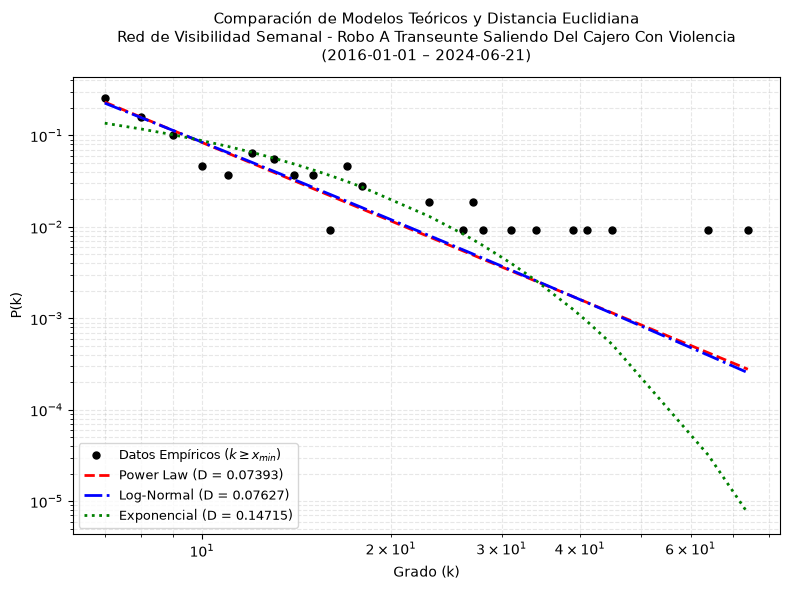

2026-10-06 14:42:55,046 - [plot_model_comparison] - INFO - EXITO.


,Modelo,Distancia Euclidiana
0,Ley de Potencia,0.073930
1,Log-Normal,0.076269
2,Exponencial,0.147152


In [45]:
# [EJECUCIÓN] Comparativa de modelos teóricos de grado
# INPUT:  visibility_graph (nx.Graph), TARGET_CRIME (str)
# OUTPUT: df_model_distances (pd.DataFrame)

try:
    df_model_distances = plot_model_comparison(visibility_graph, TARGET_CRIME)
    display(df_model_distances)
except Exception as err:
    logger.error(f"Fallo en la comparación de modelos: {err}")

<details>
<summary><b>Análisis Estadístico: Validación Formal CSN (Clauset-Shalizi-Newman)</b></summary>

<br>

Aplica el protocolo riguroso de Clauset, Shalizi y Newman (2009) para contrastar la hipótesis de libre de escala en la red de visibilidad.

#### Parámetros estadísticos calculados
* **Exponente de escala ($\gamma$):** Estimador de máxima verosimilitud con desviación estándar asintótica ($\sigma$).
* **Punto de corte óptimo ($X_{\min}$):** Minimización de la distancia de Kolmogorov-Smirnov ($D_{KS}$).
* **Validación absoluta:** Distancia $D$ respecto a la distribución acumulada empírica.
* **Test de Razón de Verosimilitud Normalizado ($R$):** Contraste frente a la alternativa lognormal con criterio de significancia ($p < 0.05$).

#### Parámetros de entrada
* **`grafo`** (`nx.Graph`): Red compleja evaluada.
* **`crime_name`** (`str`): Delito bajo estudio para el encabezado del gráfico.

#### Retorno
* **`dict`**: Diccionario estructurado con los estimadores analíticos y el veredicto del test de razón de verosimilitud.

</details>

In [46]:
# [HELPERS] Validación analítica de Ley de Potencia bajo metodología CSN
# INPUT:  grafo (nx.Graph), crime_name (str)
# OUTPUT: dict

def plot_csn_analysis(grafo: nx.Graph, crime_name: str) -> dict:
    """Calcula y grafica el análisis de Ley de Potencia bajo metodología CSN."""
    logger.info("Iniciando análisis riguroso CSN")
    if grafo.number_of_nodes() == 0:
        logger.warning("El grafo recibido está vacío.")
        return {}

    # 1. Extracción de grados positivos
    data = np.array([d for _, d in grafo.degree() if d > 0])
    if len(data) == 0:
        logger.warning("El grafo no contiene nodos con grado positivo.")
        return {}

    # 2. Ajuste matemático con supresión de advertencias de convergencia
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=OptimizeWarning)
        fit = powerlaw.Fit(data, discrete=True, verbose=False)
        R_log, p_comp = fit.distribution_compare(
            "power_law", "lognormal", normalized_ratio=True
        )

    ks_distancia = float(fit.power_law.D)
    gamma_val = float(fit.power_law.alpha)
    sigma_val = float(fit.power_law.sigma)
    xmin_val = float(fit.power_law.xmin)
    total_nodos = len(data)
    nodos_cumplen = int(np.sum(data >= xmin_val))

    # Criterio de verosimilitud relativa
    if p_comp < 0.05:
        veredicto = "Power Law" if R_log > 0 else "Lognormal"
    else:
        veredicto = "Inconclusivo (Ambas)"

    # 3. Formateo de fechas para el título
    fechas = [
        pd.to_datetime(d["fecha_hecho"])
        for _, d in grafo.nodes(data=True)
        if "fecha_hecho" in d
    ]
    rango_fechas = (
        f"({min(fechas).strftime('%Y-%m-%d')} – {max(fechas).strftime('%Y-%m-%d')})"
        if fechas
        else "(Periodo Desconocido)"
    )

    titulo_grafico = (
        f"Distribución de Grado P(k) y Ajuste de Ley de Potencia (CSN)\n"
        f"Red de Visibilidad Semanal - {crime_name.title()}\n"
        f"{rango_fechas}"
    )

    # 4. Renderizado del gráfico
    plt.figure(figsize=(7, 5), dpi=100)
    fit.plot_pdf(
        color="black",
        marker="o",
        linestyle="None",
        markersize=5,
        label="Datos Empíricos",
    )
    fit.power_law.plot_pdf(
        color="red",
        linestyle="--",
        linewidth=2,
        label="Ajuste Óptimo Power Law",
    )

    # 5. Anotaciones de métricas
    texto_stats = (
        r"$\mathbf{Métricas\ del\ Ajuste:}$" + "\n"
        f"Exponente Gamma ($\\gamma$): {gamma_val:.4f} $\\pm$ {sigma_val:.4f}\n"
        f"Corte Inferior ($X_{{min}}$): {xmin_val:.2f}\n"
        f"Nodos ($k \\geq X_{{min}}$): {nodos_cumplen} / {total_nodos} "
        f"({nodos_cumplen / total_nodos * 100:.1f}%)\n\n"
        r"$\mathbf{Validación\ Absoluta:}$" + "\n"
        f"Distancia KS (D): {ks_distancia:.4f}\n\n"
        r"$\mathbf{Comparación\ Relativa:}$" + "\n"
        f"R (Log-Likelihood): {R_log:.4f}\n"
        f"p-value (Comp): {p_comp:.4f}\n"
        f"Ganador: {veredicto}"
    )

    plt.text(
        0.05,
        0.05,
        texto_stats,
        transform=plt.gca().transAxes,
        fontsize=8,
        verticalalignment="bottom",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.9),
    )

    plt.title(titulo_grafico, fontsize=11, pad=15)
    plt.xlabel("Grado (k)", fontsize=10)
    plt.ylabel("P(k)", fontsize=10)
    plt.xscale("log")
    plt.yscale("log")
    plt.grid(True, which="both", ls="--", alpha=0.3)
    plt.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.show()

    logger.info("EXITO.")
    return {
        "gamma": gamma_val,
        "sigma": sigma_val,
        "xmin": xmin_val,
        "ks_distancia": ks_distancia,
        "R_log": R_log,
        "p_value": p_comp,
        "veredicto": veredicto,
    }

<details>
<summary><b>Ejecución: Protocolo estadístico CSN</b></summary>

<br>

Ejecuta `plot_csn_analysis` sobre `visibility_graph` para estimar los parámetros de máxima verosimilitud de la red y almacena los resultados en `csn_metrics`.

#### Variables generadas
* **`csn_metrics`** (`dict`): Diccionario con los parámetros formales $\gamma$, $x_{\min}$, $D_{KS}$ y el resultado del test relativo.

</details>

2026-10-06 14:43:00,971 - [plot_csn_analysis] - INFO - Iniciando análisis riguroso CSN


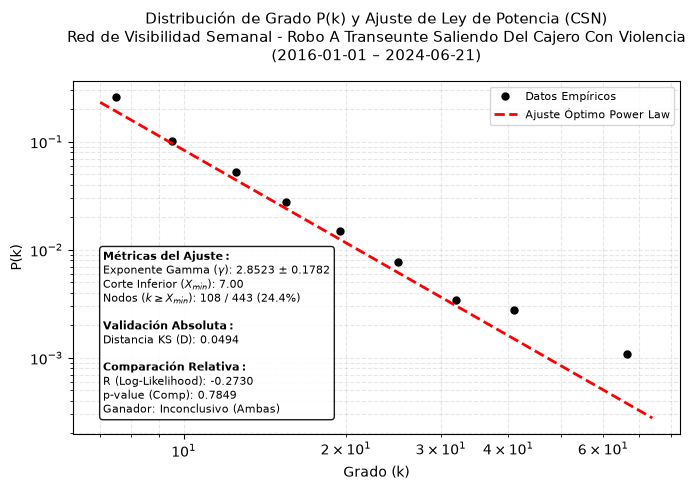

2026-10-06 14:43:01,537 - [plot_csn_analysis] - INFO - EXITO.
2026-10-06 14:43:01,538 - [<module>] - INFO - Veredicto CSN: Inconclusivo (Ambas)


In [47]:
# [EJECUCIÓN] Evaluación estadística bajo protocolo CSN
# INPUT:  visibility_graph (nx.Graph), TARGET_CRIME (str)
# OUTPUT: csn_metrics (dict)

try:
    csn_metrics = plot_csn_analysis(visibility_graph, TARGET_CRIME)
    logger.info(f"Veredicto CSN: {csn_metrics.get('veredicto')}")
except Exception as err:
    logger.error(f"Fallo en la evaluación CSN: {err}")

<details>
<summary><b>Helpers: Catálogo de referencia y perfiles de fragmentación</b></summary>

<br>

Define los componentes atómicos para construir modelos teóricos de control calibrados a $N$ y $\rho$, y simula la fragmentación progresiva de la red mediante remoción secuencial de nodos.

#### Funciones definidas
* **`sequential_regular_graph`**: Genera cadenas regulares con memoria local de alcance $k$.
* **`generate_benchmark_models`**: Construye el catálogo de grafos sintéticos calibrados al tamaño y densidad de la red empírica.
* **`simulate_node_removal_profile`**: Devuelve el vector discreto $C(r)$ (número de componentes conexas) bajo ataque dirigido o falla aleatoria.

</details>

In [48]:
# [HELPERS] Componentes atómicos para generación de modelos de control y simulación de remoción
# INPUT:  grafo (nx.Graph) / grafo (nx.Graph), sorting_strategy (str), seed (int)
# OUTPUT: dict[str, nx.Graph] / np.ndarray

# sequential regular graph originalmente enlace_igualitario
def sequential_regular_graph(n: int, k: int) -> nx.Graph:
    """Genera un grafo lineal regular donde cada nodo i se conecta hacia adelante con min(i+k, n-1)."""
    g = nx.Graph()
    g.add_nodes_from(range(n))
    for i in range(n):
        for j in range(i + 1, min(i + k + 1, n)):
            g.add_edge(i, j)
    return g


def generate_benchmark_models(grafo: nx.Graph) -> dict[str, nx.Graph]:
    """Genera el catálogo de modelos teóricos calibrados al tamaño N y densidad empírica del grafo recibido."""
    if not isinstance(grafo, nx.Graph) or grafo.number_of_nodes() <= 1:
        return {}

    n_nodes = grafo.number_of_nodes()
    n_edges = grafo.number_of_edges()
    density_val = float(nx.density(grafo))
    sqrt_nodes = int(np.sqrt(n_nodes))

    modelos = {
        f"Erdos Renyi (p={density_val:.4f})": nx.erdos_renyi_graph(
            n_nodes, density_val, seed=42
        ),
        "Barabasi Albert (m=2)": (
            nx.barabasi_albert_graph(n_nodes, 2, seed=42)
            if n_nodes > 2
            else None
        ),
        "Barabasi Albert (m=3)": (
            nx.barabasi_albert_graph(n_nodes, 3, seed=42)
            if n_nodes > 3
            else None
        ),
        "Barabasi Albert (m=4)": (
            nx.barabasi_albert_graph(n_nodes, 4, seed=42)
            if n_nodes > 4
            else None
        ),
        f"Watts Strogatz (p={density_val:.4f})": (
            nx.watts_strogatz_graph(n_nodes, 4, density_val, seed=42)
            if n_nodes >= 4
            else None
        ),
        "Random Regular (k=2)": (
            nx.random_regular_graph(2, n_nodes, seed=42)
            if n_nodes > 2
            else None
        ),
        # sequential regular graph originalmente enlace_igualitario
        "Cadena Regular (k=1)": sequential_regular_graph(n_nodes, 1),
        # Cadena lineal con memoria de 2 semanas hacia adelante (control de correlación local)
        "Cadena Regular (k=2)": sequential_regular_graph(n_nodes, 2),
        "Star": nx.star_graph(n_nodes - 1) if n_nodes > 0 else None,
        "Grid 2D": (
            nx.grid_2d_graph(sqrt_nodes, sqrt_nodes)
            if sqrt_nodes > 0
            else None
        ),
        "Ladder": nx.ladder_graph(n_nodes // 2) if n_nodes >= 2 else None,
        "Hypercube": (
            nx.hypercube_graph(int(np.log2(n_nodes)))
            if (n_nodes > 0 and (n_nodes & (n_nodes - 1)) == 0)
            else None
        ),
        "Complete": nx.complete_graph(n_nodes),
        # Path equivale exactamente al enlace secuencial con k=1
        "Path": nx.path_graph(n_nodes),
        "Cycle": nx.cycle_graph(n_nodes),
        "Circular Ladder": (
            nx.circular_ladder_graph(n_nodes // 2) if n_nodes >= 2 else None
        ),
    }

    # Descartar modelos que no pudieron instanciarse (valores None)
    return {nombre: g for nombre, g in modelos.items() if g is not None}


def simulate_node_removal_profile(grafo: nx.Graph, sorting_strategy: str = "ataque", seed: int = 42) -> np.ndarray:
    """Calcula la curva de fragmentación (componentes conexos resultantes) bajo una estrategia de remoción."""
    g_copy = grafo.copy()
    n_nodes = g_copy.number_of_nodes()

    if n_nodes == 0:
        return np.array([])

    if sorting_strategy == "ataque":
        nodos_ordenados = sorted(g_copy.nodes(), key=lambda u: g_copy.degree(u), reverse=True)
    elif sorting_strategy == "aleatorio":
        rng = random.Random(seed)
        nodos_ordenados = rng.sample(list(g_copy.nodes()), n_nodes)
    else:
        raise ValueError(
            f"Estrategia '{sorting_strategy}' no reconocida. Use 'ataque' o 'aleatorio'."
        )

    componentes = []
    for nodo in nodos_ordenados:
        if nodo in g_copy:
            g_copy.remove_node(nodo)
        componentes.append(nx.number_connected_components(g_copy))

    return np.array(componentes)

<details>
<summary><b>Ejemplo: Generación de modelos y simulación</b></summary>

<br>

Instancia el catálogo sintético de referencia calibrado y calcula la curva de fragmentación bajo ataque dirigido sobre `visibility_graph`.

#### Variables generadas
* **`catalogo_modelos`** (`dict`): Conjunto de grafos teóricos calibrados a $N$ y $\rho$.
* **`curva_empirica`** (`np.ndarray`): Vector con el conteo de componentes conexas paso a paso.

</details>

In [49]:
# Ejemplo de consumo directo y limpio:
catalogo_modelos = generate_benchmark_models(visibility_graph)
curva_empirica = simulate_node_removal_profile(visibility_graph, sorting_strategy="ataque")

<details>
<summary><b>Visualización: Cuadrícula comparativa de resiliencia estructural</b></summary>

<br>

Grafica la cuadrícula completa de curvas de fragmentación (Ataque Dirigido vs. Falla Aleatoria) para la red empírica y los modelos sintéticos de control, calculando las métricas base de la ventana.

#### Parámetros calculados
* **`df_params`** (`pd.DataFrame`): Tabla con los invariantes de escala de la ventana: nodos ($N$), enlaces ($m$), grado promedio ($\langle k \rangle$) y densidad ($p$).

</details>

In [50]:
# [VISUALIZACIÓN] Cuadrícula comparativa de fragmentación estructural
# INPUT:  grafo (nx.Graph), crime_name (str)
# OUTPUT: pd.DataFrame
import math
import matplotlib.pyplot as plt
import pandas as pd


def evaluate_network_resilience_grid(grafo: nx.Graph, crime_name: str) -> pd.DataFrame:
    """Genera una cuadrícula de curvas de fragmentación para la red empírica y los modelos teóricos."""
    logger.info("Iniciando evaluación comparada de resiliencia estructural")
    if getattr(grafo, "number_of_nodes", lambda: 0)() == 0:
        logger.warning("El grafo recibido está vacío.")
        return pd.DataFrame()

    # 1. Parámetros empíricos básicos de la ventana
    n_nodes = grafo.number_of_nodes()
    n_edges = grafo.number_of_edges()
    density_val = float(nx.density(grafo)) if n_nodes > 1 else 0.0
    k_avg = (
        sum(dict(grafo.degree()).values()) / n_nodes if n_nodes > 0 else 0.0
    )

    df_params = pd.DataFrame(
        {
            "Métrica": [
                "Nodos (Semanas)",
                "Enlaces (m)",
                "Grado Promedio (k)",
                "Densidad (p)",
            ],
            "Valor": [
                n_nodes,
                n_edges,
                round(k_avg, 4),
                round(density_val, 4),
            ],
        }
    )

    # 2. Catálogo completo: Red real + Modelos sintéticos de control
    modelos_sinteticos = generate_benchmark_models(grafo)
    catalogo = {"Red Empírica Semanal": grafo, **modelos_sinteticos}

    # 3. Formateo de fechas para el encabezado
    fechas = [
        pd.to_datetime(d["fecha_hecho"])
        for _, d in grafo.nodes(data=True)
        if "fecha_hecho" in d
    ]
    rango_fechas = (
        f"({min(fechas).strftime('%Y-%m-%d')} – {max(fechas).strftime('%Y-%m-%d')})"
        if fechas
        else "(Periodo Desconocido)"
    )

    # 4. Estrategias a evaluar
    estrategias = [
        ("Ataque Dirigido (Nodos de Mayor Grado)", "ataque"),
        ("Falla Aleatoria (Nodos al Azar)", "aleatorio"),
    ]

    # 5. Generación de las figuras
    for titulo_estrategia, estrategia_key in estrategias:
        total_modelos = len(catalogo)
        filas = math.ceil(total_modelos / 5)

        fig, axes = plt.subplots(
            filas, 5, figsize=(18, 3.5 * filas), constrained_layout=True
        )
        axes = axes.flatten()

        for i, (nombre_red, red_obj) in enumerate(catalogo.items()):
            # Llamada al simulador atómico
            curva = simulate_node_removal_profile(red_obj, sorting_strategy=estrategia_key)

            # Resaltar la red empírica en azul oscuro y los modelos teóricos en gris/azul estándar
            color_linea = (
                "crimson"
                if nombre_red == "Red Empírica Semanal"
                else "royalblue"
            )

            axes[i].plot(curva, color=color_linea, linewidth=1.8)
            axes[i].set_title(nombre_red, fontsize=9)
            axes[i].set_xlabel("Nodos removidos", fontsize=8)
            axes[i].set_ylabel("Componentes conexos", fontsize=8)
            axes[i].grid(True, linestyle="--", alpha=0.3)

        # Ocultar subplots vacíos al final de la última fila
        for j in range(total_modelos, len(axes)):
            axes[j].set_visible(False)

        fig.suptitle(
            f"{titulo_estrategia}\n"
            f"Red de Visibilidad Semanal - {crime_name.title()}\n"
            f"{rango_fechas}",
            fontsize=13,
            fontweight="bold",
        )
        plt.show()

    logger.info("EXITO.")
    return df_params

<details>
<summary><b>Ejecución: Evaluación de resiliencia en cuadrícula comparativa</b></summary>

<br>

Ejecuta `evaluate_network_resilience_grid` sobre `visibility_graph` para trazar los perfiles de remoción de todos los modelos bajo ataque y falla, almacenando los invariantes base de la ventana.

#### Variables generadas
* **`df_resilience_scalars`** (`pd.DataFrame`): Tabla con los valores escalares calculados ($N$, $m$, $\langle k \rangle$, $p$) para la ventana temporal activa.

</details>

2026-10-06 14:43:13,244 - [evaluate_network_resilience_grid] - INFO - Iniciando evaluación comparada de resiliencia estructural


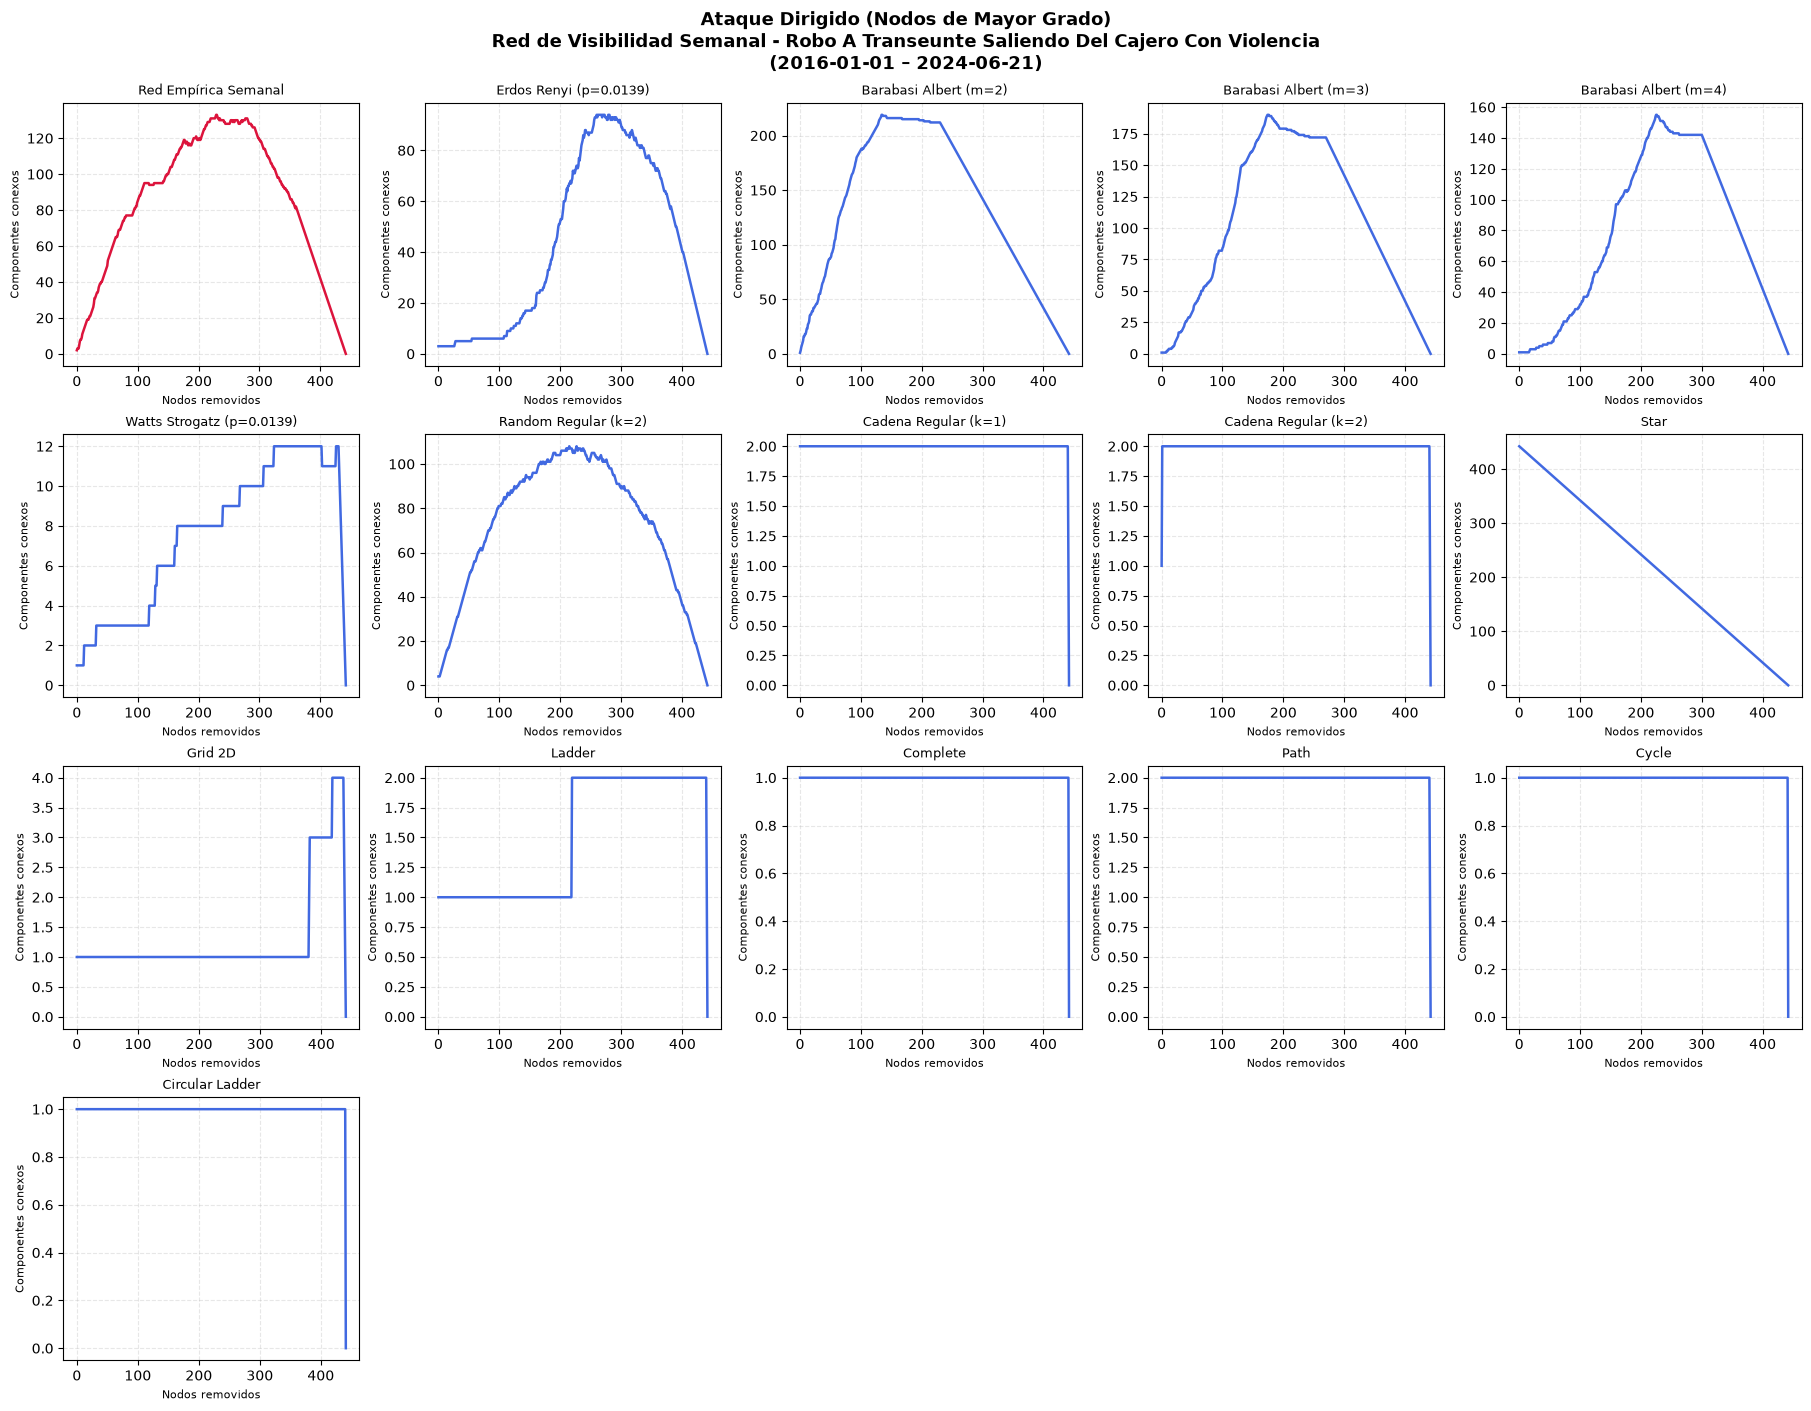

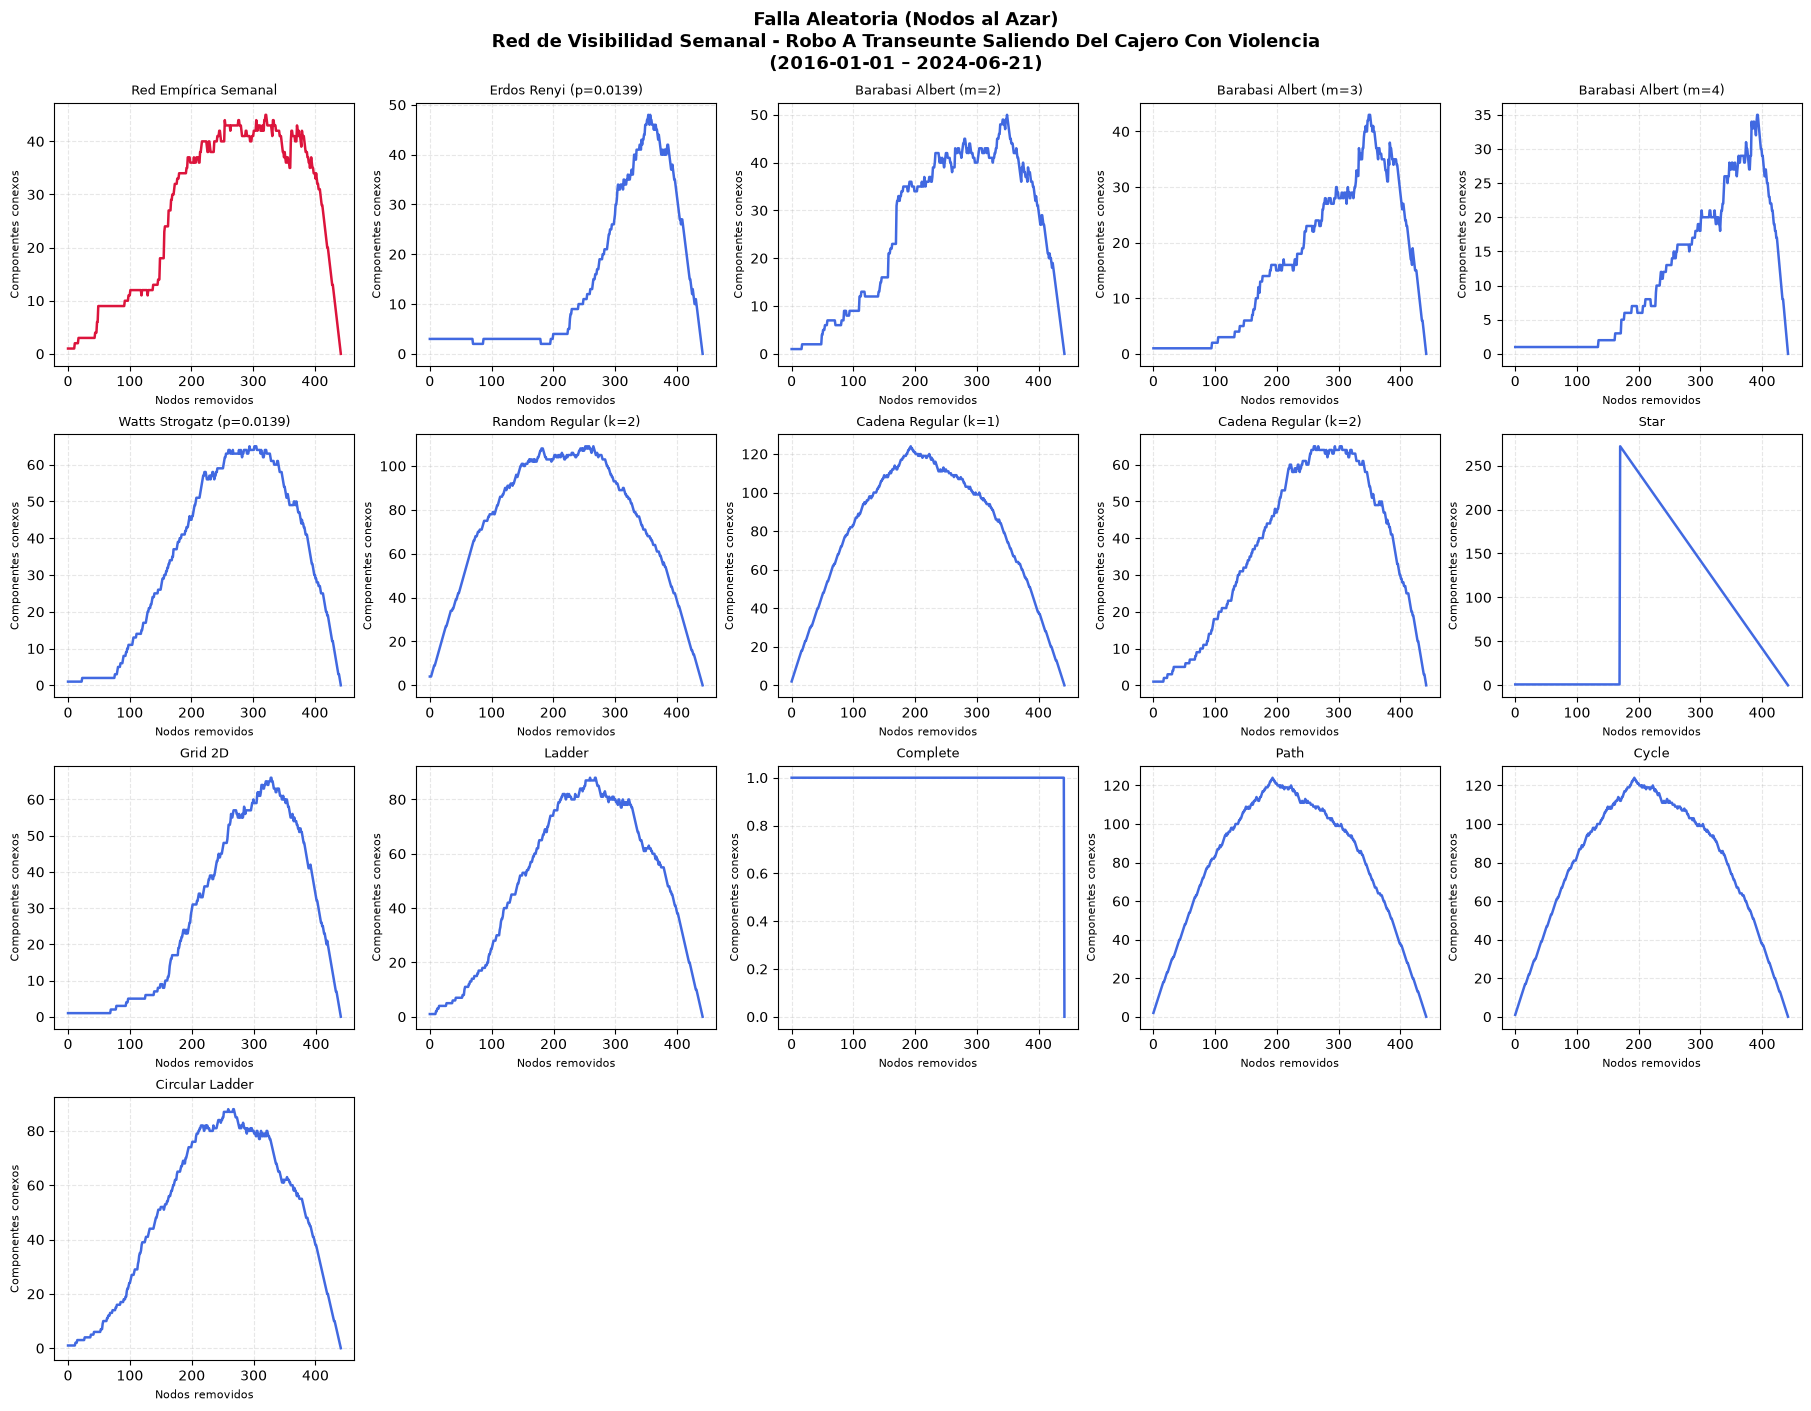

2026-10-06 14:43:19,915 - [evaluate_network_resilience_grid] - INFO - EXITO.
2026-10-06 14:43:19,922 - [<module>] - INFO - Resumen de parámetros base calculados:
              Métrica      Valor
0     Nodos (Semanas)   443.0000
1         Enlaces (m)  1356.0000
2  Grado Promedio (k)     6.1219
3        Densidad (p)     0.0139


,Métrica,Valor
0,Nodos (Semanas),443.0000
1,Enlaces (m),1356.0000
2,Grado Promedio (k),6.1219
3,Densidad (p),0.0139


In [51]:
# [EJECUCIÓN] Evaluación de resiliencia estructural en cuadrícula comparativa
# INPUT:  visibility_graph (nx.Graph), CRIME_NAME (str)
# OUTPUT: df_resilience_scalars (pd.DataFrame)

try:
    df_resilience_scalars = evaluate_network_resilience_grid(
        grafo=visibility_graph, crime_name=TARGET_CRIME
    )
    logger.info(
        f"Resumen de parámetros base calculados:\n{df_resilience_scalars}"
    )
    display(df_resilience_scalars)
except Exception as err:
    logger.error(
        f"Fallo al ejecutar la cuadrícula de resiliencia estructural: {err}"
    )

<details>
<summary><b>Helpers: Distancia euclidiana normalizada</b></summary>

<br>

Calcula la distancia euclidiana entre dos curvas de fragmentación escaladas por su valor máximo respectivo, permitiendo comparar la trayectoria de desmantelamiento sin sesgo por escala.

#### Salida
* Retorna un escalar (`float`) correspondiente a la métrica $D = \Vert{}\mathbf{y}_1^{\text{norm}} - \mathbf{y}_2^{\text{norm}}\Vert{}_2$.

</details>

In [52]:
# [HELPERS] Cálculo de distancia euclidiana entre curvas normalizadas
# INPUT:  y1 (np.ndarray), y2 (np.ndarray)
# OUTPUT: float


def compute_normalized_curve_distance(y1: np.ndarray, y2: np.ndarray) -> float:
    """Calcula la distancia euclidiana normalizada al pico máximo entre dos curvas de fragmentación."""
    min_len = min(len(y1), len(y2))
    if min_len == 0:
        return float(np.nan)

    y1_trim, y2_trim = y1[:min_len], y2[:min_len]
    max_y1 = max(y1_trim) if len(y1_trim) > 0 else 0
    max_y2 = max(y2_trim) if len(y2_trim) > 0 else 0

    y1_norm = y1_trim / max_y1 if max_y1 > 0 else y1_trim
    y2_norm = y2_trim / max_y2 if max_y2 > 0 else y2_trim

    return float(np.sqrt(np.sum((y1_norm - y2_norm) ** 2)))

<details>
<summary><b>Visualización: Contraste con el modelo sintético más cercano</b></summary>

<br>

Identifica el modelo teórico que minimiza la distancia euclidiana normalizada $D$ frente a la red empírica y grafica el contraste directo en dos paneles (Ataque Dirigido vs. Falla Aleatoria).

#### Parámetros calculados
* **`df_closest_models`** (`pd.DataFrame`): Tabla resumen con el modelo óptimo seleccionado, su distancia mínima $D$ y los parámetros de escala ($k$, $p$) por cada estrategia.

</details>

In [53]:
# [VISUALIZACIÓN] Identificación y contraste del modelo sintético más cercano
# INPUT:  grafo (nx.Graph), crime_name (str)
# OUTPUT: pd.DataFrame
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def plot_closest_resilience_models(
    grafo: nx.Graph, crime_name: str
) -> pd.DataFrame:
    """Identifica el modelo teórico más cercano por distancia euclidiana y grafica la comparativa en dos paneles."""
    logger.info(
        "Identificando modelos sintéticos más cercanos por distancia estructural"
    )
    if getattr(grafo, "number_of_nodes", lambda: 0)() == 0:
        logger.warning("El grafo recibido está vacío.")
        return pd.DataFrame()

    # 1. Catálogo de modelos de referencia
    modelos_validos = generate_benchmark_models(grafo)

    # 2. Formateo de fechas para el encabezado
    fechas = [
        pd.to_datetime(d["fecha_hecho"])
        for _, d in grafo.nodes(data=True)
        if "fecha_hecho" in d
    ]
    rango_fechas = (
        f"({min(fechas).strftime('%Y-%m-%d')} – {max(fechas).strftime('%Y-%m-%d')})"
        if fechas
        else "(Periodo Desconocido)"
    )

    # 3. Estrategias de desmantelamiento
    estrategias = [
        ("Ataque Dirigido (Grado Alto)", "ataque"),
        ("Falla Aleatoria", "aleatorio"),
    ]

    fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
    resultados = []

    # 4. Evaluación comparativa por estrategia
    for idx, (nombre_estrategia, estrategia_key) in enumerate(estrategias):
        # Curva de la red real
        curva_base = simulate_node_removal_profile(
            grafo, sorting_strategy=estrategia_key, seed=42
        )

        distancias = []
        for nombre_modelo, g_teorico in modelos_validos.items():
            curva_teorica = simulate_node_removal_profile(
                g_teorico, sorting_strategy=estrategia_key, seed=42
            )
            distancia = compute_normalized_curve_distance(
                curva_base, curva_teorica
            )
            distancias.append((nombre_modelo, curva_teorica, distancia))

        # Seleccionar el modelo con menor distancia
        mejor_nombre, mejor_curva, mejor_d = sorted(
            distancias, key=lambda item: item[2]
        )[0]

        # Extracción de parámetros k y p mediante expresiones regulares
        k_match = re.search(r"[kK]=(\d+)", mejor_nombre)
        p_match = re.search(r"[pP]=([\d\.]+)", mejor_nombre)

        resultados.append(
            {
                "Estrategia": nombre_estrategia,
                "Modelo": mejor_nombre,
                "Distancia (D)": round(mejor_d, 4),
                "Parametro k": int(k_match.group(1)) if k_match else "N/A",
                "Parametro p": float(p_match.group(1)) if p_match else "N/A",
            }
        )

        # Trazado del panel actual
        ax = axes[idx]
        ax.plot(
            curva_base,
            label=f"Red Empírica: {crime_name.title()}",
            linewidth=2.5,
            color="royalblue",
            zorder=3,
        )
        ax.plot(
            mejor_curva,
            label=f"Más cercano: {mejor_nombre}\n(D={mejor_d:.4f})",
            linestyle="--",
            color="crimson",
            linewidth=2.0,
            zorder=2,
        )

        ax.set_title(nombre_estrategia, fontsize=12, fontweight="bold")
        ax.set_xlabel("Nodos eliminados (Semanas)", fontsize=10)
        ax.set_ylabel("Componentes conexos", fontsize=10)
        ax.legend(fontsize=9, loc="best")
        ax.grid(True, linestyle="--", alpha=0.4)

    fig.suptitle(
        f"Contraste de Desmantelamiento vs. Modelo Sintético Más Cercano\n"
        f"Red de Visibilidad Semanal - {crime_name.title()}\n"
        f"{rango_fechas}",
        fontsize=13,
        fontweight="bold",
    )
    plt.show()

    logger.info("EXITO.")
    return pd.DataFrame(resultados)

<details>
<summary><b>Ejecución: Contraste con el modelo sintético óptimo</b></summary>

<br>

Ejecuta `plot_closest_resilience_models` sobre `visibility_graph` para determinar el modelo sintético que mejor aproxima la curva de fragmentación empírica y renderizar los paneles comparativos.

#### Variables generadas
* **`df_closest_models`** (`pd.DataFrame`): Tabla con los modelos teóricos de menor distancia $D$ hallados para ataque y falla.

</details>

2026-10-06 14:43:21,276 - [plot_closest_resilience_models] - INFO - Identificando modelos sintéticos más cercanos por distancia estructural


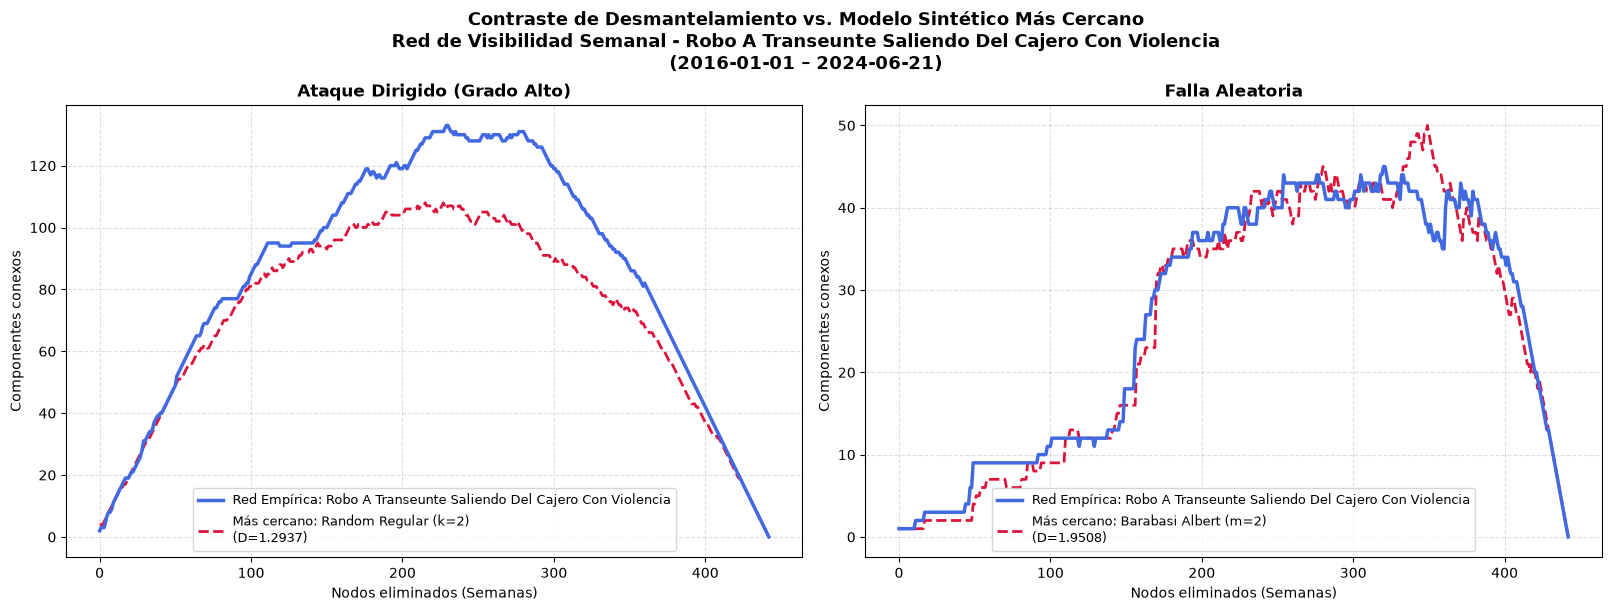

2026-10-06 14:43:23,634 - [plot_closest_resilience_models] - INFO - EXITO.
2026-10-06 14:43:23,643 - [<module>] - INFO - Modelos teóricos con menor distancia hallados:
                     Estrategia                 Modelo  Distancia (D)  \
0  Ataque Dirigido (Grado Alto)   Random Regular (k=2)         1.2937   
1               Falla Aleatoria  Barabasi Albert (m=2)         1.9508   

  Parametro k Parametro p  
0           2         N/A  
1         N/A         N/A  


,Estrategia,Modelo,Distancia (D),Parametro k,Parametro p
0,Ataque Dirigido (Grado Alto),Random Regular (k=2),1.2937,2,N/A
1,Falla Aleatoria,Barabasi Albert (m=2),1.9508,N/A,N/A


In [54]:
# [EJECUCIÓN] Búsqueda del modelo sintético con menor distancia estructural
# INPUT:  visibility_graph (nx.Graph), CRIME_NAME (str)
# OUTPUT: df_closest_models (pd.DataFrame)

try:
    df_closest_models = plot_closest_resilience_models(
        grafo=visibility_graph, crime_name=TARGET_CRIME
    )
    logger.info(
        f"Modelos teóricos con menor distancia hallados:\n{df_closest_models}"
    )
    display(df_closest_models)
except Exception as err:
    logger.error(f"Fallo al contrastar modelos sintéticos cercanos: {err}")

In [55]:
# [HELPERS] Extracción temporal de modelos de resiliencia más cercanos
# INPUT:  rolling_graphs (list[dict]), crime_name (str)
# OUTPUT: pd.DataFrame
import re
import numpy as np
import pandas as pd


def extract_rolling_resilience_scalars(
    rolling_graphs: list[dict], crime_name: str
) -> pd.DataFrame:
    """Calcula para cada ventana temporal los modelos sintéticos de menor distancia estructural."""
    logger.info(
        f"Iniciando extracción de resiliencia sobre {len(rolling_graphs)} ventanas temporales"
    )

    if not rolling_graphs:
        logger.warning("La lista de grafos temporales está vacía.")
        return pd.DataFrame()

    registros = []
    estrategias = [("ataque", "ataque"), ("falla", "aleatorio")]

    for item in rolling_graphs:
        w_id = item["window_id"]
        g = item["graph"]
        start_dt = item["start_date"]
        end_dt = item["end_date"]

        if getattr(g, "number_of_nodes", lambda: 0)() == 0:
            continue

        # Invariantes base de la ventana
        n_nodes = g.number_of_nodes()
        n_edges = g.number_of_edges()
        density_val = float(nx.density(g)) if n_nodes > 1 else 0.0

        # Catálogo calibrado a esta ventana específica
        catalogo = generate_benchmark_models(g)

        fila = {
            "window_id": w_id,
            "crime_name": crime_name,
            "start_date": start_dt,
            "end_date": end_dt,
            "nodes": n_nodes,
            "edges": n_edges,
            "density": round(density_val, 4),
        }

        # Evaluación para Ataque y Falla
        for sufijo, est_key in estrategias:
            curva_real = simulate_node_removal_profile(
                g, sorting_strategy=est_key, seed=42
            )

            distancias = []
            for nombre_mod, g_teo in catalogo.items():
                curva_teo = simulate_node_removal_profile(
                    g_teo, sorting_strategy=est_key, seed=42
                )
                dist = compute_normalized_curve_distance(curva_real, curva_teo)
                distancias.append((nombre_mod, dist))

            mejor_nombre, mejor_d = sorted(
                distancias, key=lambda item: item[1]
            )[0]

            # Parámetros k y p
            k_match = re.search(r"[kK]=(\d+)", mejor_nombre)
            p_match = re.search(r"[pP]=([\d\.]+)", mejor_nombre)

            fila[f"modelo_{sufijo}"] = mejor_nombre
            fila[f"distancia_{sufijo}"] = round(mejor_d, 4)
            fila[f"k_{sufijo}"] = int(k_match.group(1)) if k_match else np.nan
            fila[f"p_{sufijo}"] = (
                float(p_match.group(1)) if p_match else np.nan
            )

        registros.append(fila)

    df_resilience_ts = pd.DataFrame(registros)
    logger.info("EXITO.")
    return df_resilience_ts

In [56]:
# [EJECUCIÓN] Procesamiento por lotes sobre todas las ventanas temporales
# INPUT:  rolling_graphs (list[dict]), TARGET_CRIME (str)
# OUTPUT: df_resilience_ts (pd.DataFrame)

try:
    df_resilience_ts = extract_rolling_resilience_scalars(
        rolling_graphs=rolling_graphs, crime_name=TARGET_CRIME
    )
    logger.info(
        f"Procesamiento completado: {len(df_resilience_ts)} ventanas evaluadas."
    )
    display(df_resilience_ts.head())
except Exception as err:
    logger.error(
        f"Fallo en la extracción de resiliencia sobre rolling windows: {err}"
    )

2026-10-06 14:43:31,003 - [extract_rolling_resilience_scalars] - INFO - Iniciando extracción de resiliencia sobre 14 ventanas temporales
2026-10-06 14:43:33,126 - [extract_rolling_resilience_scalars] - INFO - EXITO.
2026-10-06 14:43:33,127 - [<module>] - INFO - Procesamiento completado: 14 ventanas evaluadas.


,window_id,crime_name,start_date,end_date,nodes,edges,density,modelo_ataque,distancia_ataque,k_ataque,p_ataque,modelo_falla,distancia_falla,k_falla,p_falla
0,0,ROBO A TRANSEUNTE SALIENDO DEL CAJERO CON VIOL...,2016-01-01,2017-12-22,104,325,0.0607,Random Regular (k=2),1.3268,2.0,NaN,Barabasi Albert (m=3),1.5720,NaN,NaN
1,1,ROBO A TRANSEUNTE SALIENDO DEL CAJERO CON VIOL...,2016-07-01,2018-06-22,104,325,0.0607,Random Regular (k=2),1.5083,2.0,NaN,Watts Strogatz (p=0.0607),1.2953,NaN,0.0607
2,2,ROBO A TRANSEUNTE SALIENDO DEL CAJERO CON VIOL...,2016-12-30,2018-12-21,104,384,0.0717,Random Regular (k=2),1.3787,2.0,NaN,Barabasi Albert (m=4),1.9474,NaN,NaN
3,3,ROBO A TRANSEUNTE SALIENDO DEL CAJERO CON VIOL...,2017-06-30,2019-06-21,104,312,0.0583,Random Regular (k=2),1.0456,2.0,NaN,Barabasi Albert (m=3),1.5439,NaN,NaN
4,4,ROBO A TRANSEUNTE SALIENDO DEL CAJERO CON VIOL...,2017-12-29,2019-12-20,104,310,0.0579,Random Regular (k=2),1.0782,2.0,NaN,Grid 2D,1.1692,NaN,NaN


In [57]:
# [VISUALIZACIÓN] Evolución longitudinal de la distancia estructural D
# INPUT:  df_resilience_ts (pd.DataFrame), crime_name (str)
# OUTPUT: None
import matplotlib.pyplot as plt
import pandas as pd


def plot_rolling_resilience_evolution(
    df_resilience_ts: pd.DataFrame, crime_name: str
) -> None:
    """Grafica la evolución temporal de la distancia euclidiana D y los modelos dominantes por ventana."""
    logger.info("Iniciando visualización temporal de distancias de resiliencia")

    if df_resilience_ts.empty:
        logger.warning(
            "El DataFrame de métricas longitudinales de resiliencia está vacío."
        )
        return

    df_plot = df_resilience_ts.copy()
    fechas_eje = pd.to_datetime(df_plot["end_date"])

    fig, axes = plt.subplots(
        2, 1, figsize=(15, 8), sharex=True, constrained_layout=True
    )

    paneles = [
        (
            0,
            "distancia_ataque",
            "modelo_ataque",
            "Ataque Dirigido (Grado Alto)",
            "crimson",
        ),
        (
            1,
            "distancia_falla",
            "modelo_falla",
            "Falla Aleatoria",
            "royalblue",
        ),
    ]

    for ax_idx, col_d, col_mod, titulo, color in paneles:
        ax = axes[ax_idx]

        # Trayectoria continua de la distancia D
        ax.plot(
            fechas_eje,
            df_plot[col_d],
            color=color,
            marker="o",
            markersize=4,
            linewidth=1.8,
            label=f"Distancia D mínima ({titulo})",
            zorder=3,
        )

        # Anotación del modelo dominante en cada ventana
        for _, row in df_plot.iterrows():
            nombre_limpio = row[col_mod].split("(")[0].strip()
            ax.annotate(
                nombre_limpio,
                (pd.to_datetime(row["end_date"]), row[col_d]),
                textcoords="offset points",
                xytext=(0, 7),
                ha="center",
                fontsize=7,
                rotation=40,
                alpha=0.85,
            )

        ax.set_title(titulo, fontsize=11, fontweight="bold")
        ax.set_ylabel("Distancia Euclidiana $D$", fontsize=9)
        ax.grid(True, linestyle="--", alpha=0.35)
        ax.legend(loc="upper right", fontsize=8)

        # Margen superior para evitar solapamiento del texto anotado
        lim_inf, lim_sup = ax.get_ylim()
        ax.set_ylim(lim_inf, lim_sup * 1.18)

    axes[1].set_xlabel("Fecha de Cierre de Ventana (Semanas)", fontsize=10)

    fig.suptitle(
        f"Evolución Longitudinal de Resiliencia Estructural ({len(df_plot)} Ventanas Anuales)\n"
        f"Delito: {crime_name.title()} | CDMX",
        fontsize=13,
        fontweight="bold",
    )
    plt.show()
    logger.info("EXITO.")

2026-10-06 14:43:41,002 - [plot_rolling_resilience_evolution] - INFO - Iniciando visualización temporal de distancias de resiliencia


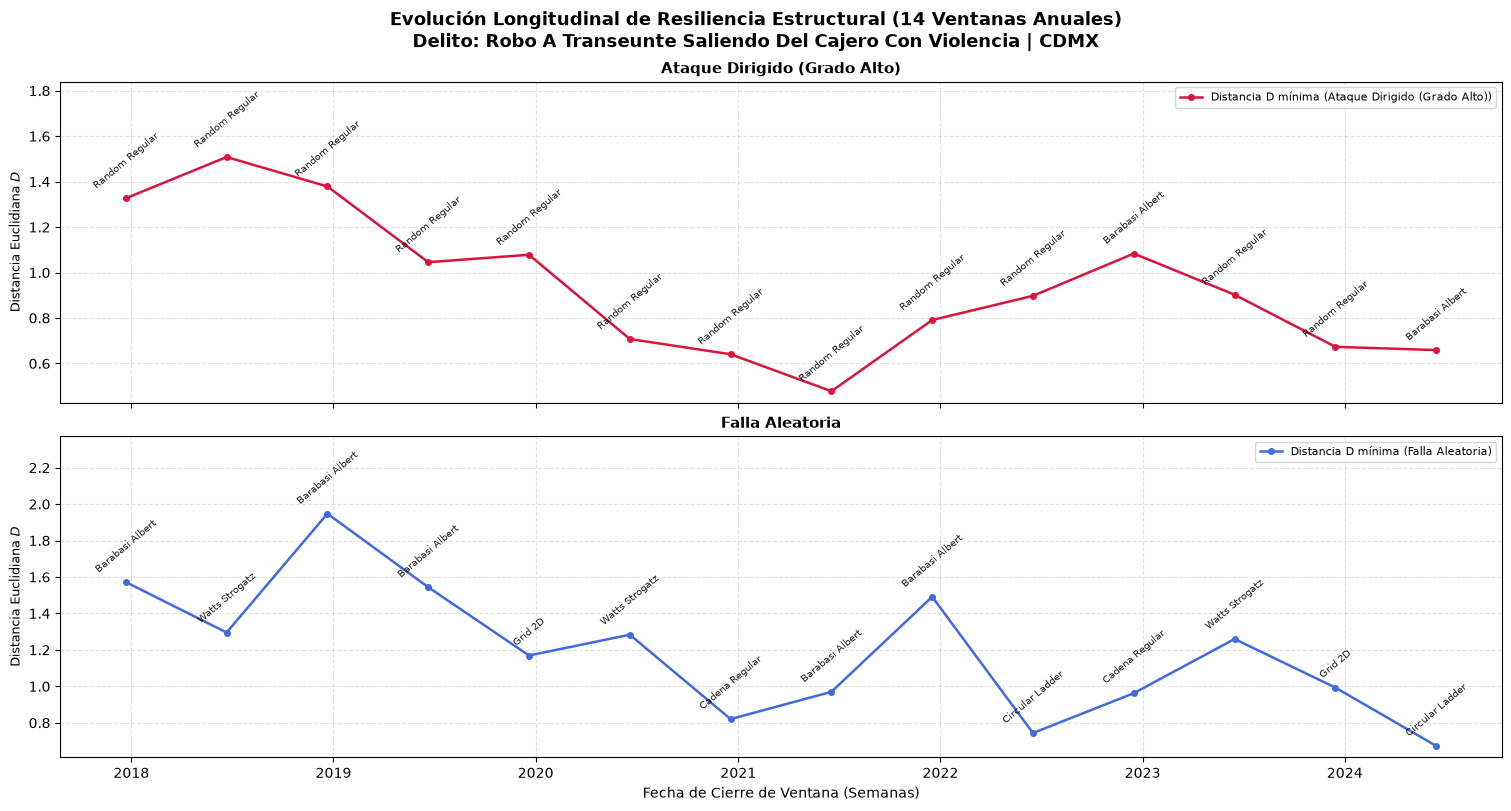

2026-10-06 14:43:41,775 - [plot_rolling_resilience_evolution] - INFO - EXITO.


In [58]:
# [EJECUCIÓN] Renderizado de la serie temporal de distancias estructurales
# INPUT:  df_resilience_ts (pd.DataFrame), TARGET_CRIME (str)
# OUTPUT: None

try:
    plot_rolling_resilience_evolution(
        df_resilience_ts=df_resilience_ts, crime_name=TARGET_CRIME
    )
except Exception as err:
    logger.error(
        f"Fallo al graficar la evolución temporal de resiliencia: {err}"
    )

In [59]:
# [VISUALIZACIÓN] Transición temporal de modelos sintéticos dominantes
# INPUT:  df_resilience_ts (pd.DataFrame), crime_name (str)
# OUTPUT: None
import matplotlib.pyplot as plt
import pandas as pd


def plot_rolling_resilience_categorical_transitions(
    df_resilience_ts: pd.DataFrame, crime_name: str
) -> None:
    """Grafica la transición entre modelos teóricos dominantes (eje Y) a lo largo del tiempo (eje X)."""
    logger.info("Iniciando visualización categórica de transición entre modelos")

    if df_resilience_ts.empty:
        logger.warning("El DataFrame de resiliencia longitudinal está vacío.")
        return

    df_plot = df_resilience_ts.copy()
    fechas_eje = pd.to_datetime(df_plot["end_date"])

    # Limpiar nombres de modelos quitando parámetros entre paréntesis para agrupar categorías
    df_plot["cat_ataque"] = (
        df_plot["modelo_ataque"].str.split("(").str[0].str.strip()
    )
    df_plot["cat_falla"] = (
        df_plot["modelo_falla"].str.split("(").str[0].str.strip()
    )

    # Catálogo único ordenado de modelos que aparecieron como ganadores
    todos_modelos = sorted(
        list(set(df_plot["cat_ataque"]).union(set(df_plot["cat_falla"])))
    )

    fig, axes = plt.subplots(
        2, 1, figsize=(15, 7), sharex=True, constrained_layout=True
    )

    paneles = [
        (
            0,
            "cat_ataque",
            "distancia_ataque",
            "Ataque Dirigido (Grado Alto)",
            "crimson",
        ),
        (1, "cat_falla", "distancia_falla", "Falla Aleatoria", "royalblue"),
    ]

    for ax_idx, col_cat, col_dist, titulo, color in paneles:
        ax = axes[ax_idx]

        # Línea tenue que une los estados temporales
        ax.plot(
            fechas_eje,
            df_plot[col_cat],
            color=color,
            linestyle="--",
            linewidth=1.2,
            alpha=0.5,
            zorder=2,
        )

        # Dispersión donde el tamaño del punto indica cercanía del ajuste (a menor D, punto más visible)
        scatter = ax.scatter(
            fechas_eje,
            df_plot[col_cat],
            c=df_plot[col_dist],
            cmap="viridis_r",
            s=90,
            edgecolor="black",
            linewidth=0.8,
            zorder=3,
        )

        # Barra de color para interpretar la distancia D
        cbar = plt.colorbar(scatter, ax=ax, aspect=20, pad=0.01)
        cbar.set_label("Distancia $D$", fontsize=8)

        ax.set_title(titulo, fontsize=11, fontweight="bold")
        ax.set_ylabel("Modelo Teórico", fontsize=9)
        ax.set_yticks(range(len(todos_modelos)))
        ax.set_yticklabels(todos_modelos, fontsize=9)
        ax.grid(True, linestyle="--", alpha=0.35)

    axes[1].set_xlabel("Fecha de Cierre de Ventana (Semanas)", fontsize=10)

    fig.suptitle(
        f"Transición Temporal de Modelos Teóricos Dominantes ({len(df_plot)} Ventanas)\n"
        f"Delito: {crime_name.title()} | CDMX",
        fontsize=13,
        fontweight="bold",
    )
    plt.show()
    logger.info("EXITO.")

In [60]:
# [VISUALIZACIÓN] Variación temporal de modelos sintéticos más próximos
# INPUT:  df_resilience_ts (pd.DataFrame), crime_name (str), window_size (int), step_size (int)
# OUTPUT: None
import matplotlib.pyplot as plt
import pandas as pd


def plot_rolling_resilience_categorical_transitions(
    df_resilience_ts: pd.DataFrame,
    crime_name: str,
    window_size: int,
    step_size: int,
) -> None:
    """Cambio entre modelos teóricos más cercanos en el eje Y a lo largo de las ventanas móviles en el eje X."""
    logger.info("Iniciando visualización categórica de transición entre modelos")

    if df_resilience_ts.empty:
        logger.warning("El DataFrame de resiliencia longitudinal está vacío.")
        return

    df_plot = df_resilience_ts.copy()

    # Eje X discreto: índice de ventana ordinal
    eje_x = df_plot["window_id"].values

    # Etiquetas formativas con intervalo real cubierto por cada ventana
    etiquetas_x = [
        f"Window {int(row.window_id)}"
        for _, row in df_plot.iterrows()
    ]

    # Limpiar nombres de modelos quitando parámetros entre paréntesis
    df_plot["cat_ataque"] = (
        df_plot["modelo_ataque"].str.split("(").str[0].str.strip()
    )
    df_plot["cat_falla"] = (
        df_plot["modelo_falla"].str.split("(").str[0].str.strip()
    )

    todos_modelos = sorted(
        list(set(df_plot["cat_ataque"]).union(set(df_plot["cat_falla"])))
    )

    fig, axes = plt.subplots(
        2, 1, figsize=(16, 8.5), sharex=True, constrained_layout=True
    )

    paneles = [
        (
            0,
            "cat_ataque",
            "distancia_ataque",
            "Ataque Dirigido (Grado Alto)",
            "crimson",
        ),
        (1, "cat_falla", "distancia_falla", "Falla Aleatoria", "royalblue"),
    ]

    for ax_idx, col_cat, col_dist, titulo, color in paneles:
        ax = axes[ax_idx]

        # Trayectoria ordinal discreta
        ax.plot(
            eje_x,
            df_plot[col_cat],
            color=color,
            linestyle="--",
            linewidth=1.2,
            alpha=0.45,
            zorder=2,
        )

        # Dispersión ponderada por distancia D
        scatter = ax.scatter(
            eje_x,
            df_plot[col_cat],
            c=df_plot[col_dist],
            cmap="viridis_r",
            s=90,
            edgecolor="black",
            linewidth=0.8,
            zorder=3,
        )

        cbar = plt.colorbar(scatter, ax=ax, aspect=20, pad=0.01)
        cbar.set_label("Distancia $D$", fontsize=8)

        ax.set_title(titulo, fontsize=11, fontweight="bold")
        ax.set_ylabel("Modelo Teórico", fontsize=9)
        ax.set_yticks(range(len(todos_modelos)))
        ax.set_yticklabels(todos_modelos, fontsize=9)

        # Despegar tanto el primer modelo de la base como el último del techo
        ax.set_ylim(-1.0, len(todos_modelos) - 1.0)

        # Margen horizontal en X para no cortar los círculos extremos
        ax.set_xlim(eje_x[0] - 0.5, eje_x[-1] + 0.5)

        ax.grid(True, linestyle="--", alpha=0.35)

    # Configuración del eje X en el panel inferior
    axes[1].set_xticks(eje_x)
    axes[1].set_xticklabels(etiquetas_x, rotation=90, fontsize=7.5)
    axes[1].set_xlabel("Secuencia de Ventanas Móviles ($W_i$)", fontsize=10)

    fig.suptitle(
        f"Cambio del Modelo Teorico mas Proximo a la Red ({len(df_plot)} Ventanas)\n"
        f"Delito: {crime_name.title()} | Ventana: {window_size} semanas | Paso: {step_size} semanas",
        fontsize=13,
        fontweight="bold",
    )
    plt.show()
    logger.info("EXITO.")

2026-10-06 14:43:53,451 - [plot_rolling_resilience_categorical_transitions] - INFO - Iniciando visualización categórica de transición entre modelos


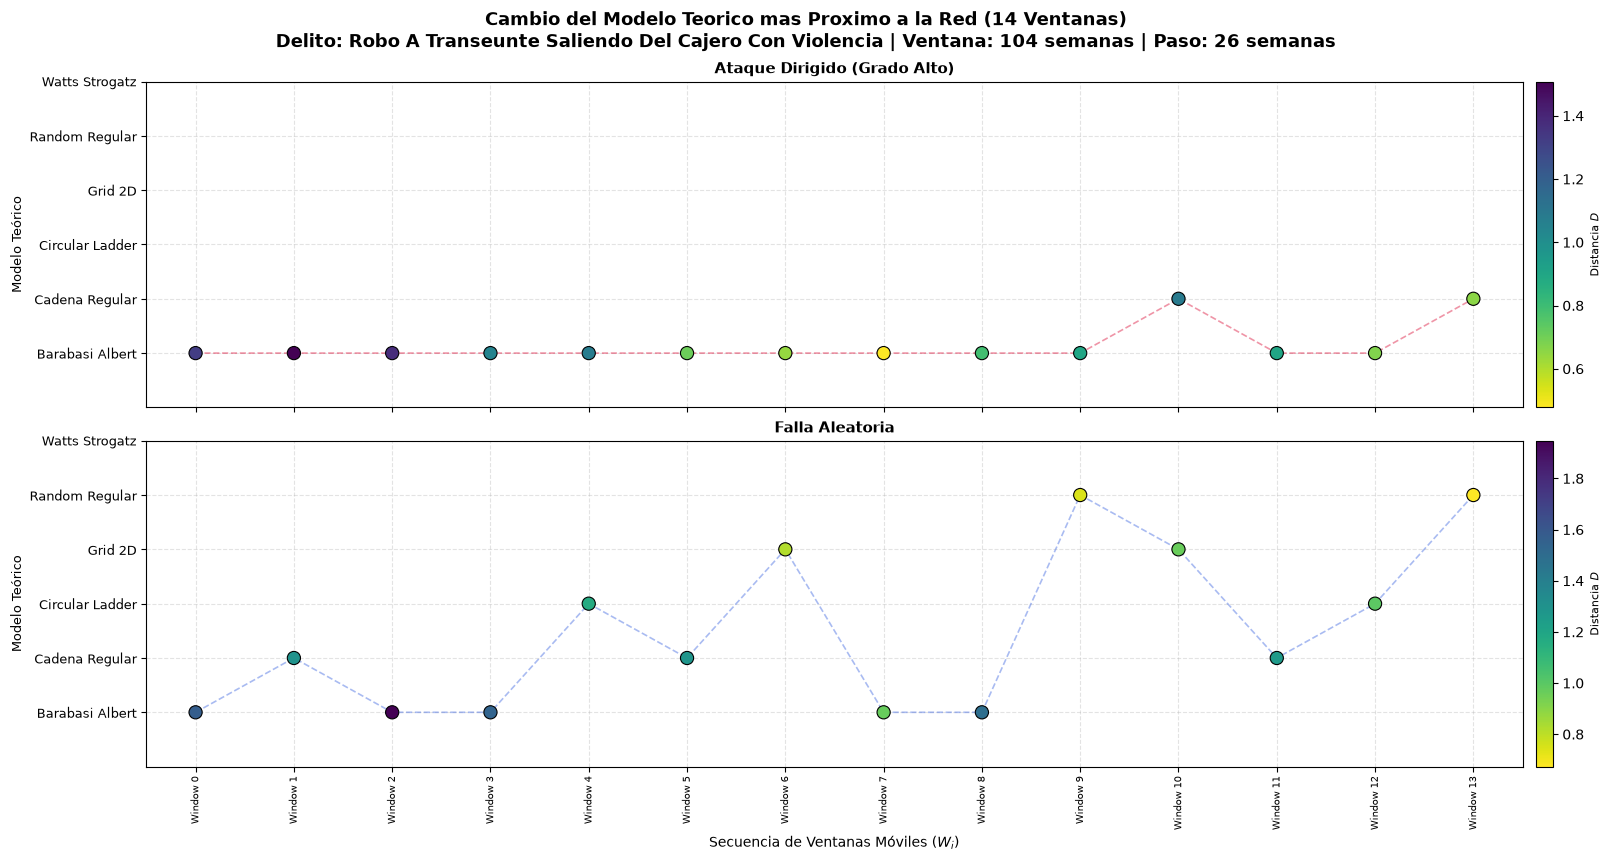

2026-10-06 14:43:53,970 - [plot_rolling_resilience_categorical_transitions] - INFO - EXITO.


In [61]:
# [EJECUCIÓN] Renderizado de la transición temporal de modelos sintéticos
# INPUT:  df_resilience_ts (pd.DataFrame), TARGET_CRIME (str), WINDOW_SIZE (int), STEP_SIZE (int)
# OUTPUT: None

try:
    plot_rolling_resilience_categorical_transitions(
        df_resilience_ts=df_resilience_ts,
        crime_name=TARGET_CRIME,
        window_size=WINDOW_SIZE,
        step_size=STEP_SIZE,
    )
except Exception as err:
    logger.error(
        f"Fallo al graficar las transiciones temporales de modelos: {err}"
    )

# DEPRECATED

<details>
<summary><b>Análisis de Resiliencia: Ataques Dirigidos vs. Fallas Aleatorias</b></summary>

<br>

Evalúa la robustez y percolación de la red de visibilidad comparándola con familias de redes teóricas y sintéticas (Erdős-Rényi, Barabási-Albert, Watts-Strogatz, redes regulares y deterministas) ante dos estrategias de desmantelamiento secuencial:
1. **Ataque Dirigido:** Eliminación priorizada de hubs (nodos ordenados descendentemente por grado).
2. **Falla Aleatoria:** Remoción estocástica uniforme de nodos.

#### Métricas observadas
* Evolución del número de componentes conexos en función de la fracción de nodos removidos.
* Cuantificación de parámetros base: tamaño $N$, volumen $M$, grado medio $\langle k \rangle$ y densidad $p$.

#### Parámetros de entrada
* **`grafo`** (`nx.Graph`): Red compleja evaluada.
* **`crime_name`** (`str`): Delito bajo estudio.

#### Retorno
* **`pd.DataFrame`**: Tabla consolidada con los parámetros estructurales base de la red empírica.

</details>

In [21]:
# [HELPERS] Simulación de resiliencia topológica y percolación
# INPUT:  grafo (nx.Graph), crime_name (str)
# OUTPUT: pd.DataFrame

def evaluate_topological_resilience(grafo: nx.Graph, crime_name: str) -> pd.DataFrame:
    """Evalúa la resiliencia de la red frente a ataques dirigidos y fallas aleatorias."""
    logger.info("Iniciando evaluación de resiliencia topológica comparada")
    if getattr(grafo, "number_of_nodes", lambda: 0)() == 0:
        logger.warning("El grafo recibido está vacío.")
        return pd.DataFrame()

    # 1. Parámetros empíricos
    n_nodes = grafo.number_of_nodes()
    n_edges = grafo.number_of_edges()
    density_val = (
        (2 * n_edges) / (n_nodes * (n_nodes - 1)) if n_nodes > 1 else 0.0
    )
    k_avg = (
        sum(dict(grafo.degree()).values()) / n_nodes if n_nodes > 0 else 0.0
    )

    df_params = pd.DataFrame(
        {
            "Métrica": [
                "Nodos (Semanas)",
                "Enlaces (m)",
                "Grado Promedio (k)",
                "Densidad (p)",
            ],
            "Valor": [
                n_nodes,
                n_edges,
                round(k_avg, 4),
                round(density_val, 4),
            ],
        }
    )

    # 2. Generación de familias de modelos teóricos
    def enlace_igualitario(n: int, k: int) -> nx.Graph:
        g = nx.Graph()
        g.add_nodes_from(range(n))
        for i in range(n):
            for j in range(i + 1, min(i + k + 1, n)):
                g.add_edge(i, j)
        return g

    sqrt_nodes = int(np.sqrt(n_nodes))
    modelos = {
        "Red Empírica Semanal": grafo,
        f"Erdos Renyi (p={density_val:.4f})": nx.erdos_renyi_graph(
            n_nodes, density_val, seed=42
        ),
        "Barabasi Albert (m=2)": (
            nx.barabasi_albert_graph(n_nodes, 2, seed=42)
            if n_nodes > 2
            else None
        ),
        "Barabasi Albert (m=3)": (
            nx.barabasi_albert_graph(n_nodes, 3, seed=42)
            if n_nodes > 3
            else None
        ),
        "Barabasi Albert (m=4)": (
            nx.barabasi_albert_graph(n_nodes, 4, seed=42)
            if n_nodes > 4
            else None
        ),
        f"Watts Strogatz (p={density_val:.4f})": (
            nx.watts_strogatz_graph(n_nodes, 4, density_val, seed=42)
            if n_nodes >= 4
            else None
        ),
        "Random Regular (k=2)": (
            nx.random_regular_graph(2, n_nodes, seed=42)
            if n_nodes > 2
            else None
        ),
        "Enlace Igualitario 2": enlace_igualitario(n_nodes, 2),
        "Enlace Igualitario 1": enlace_igualitario(n_nodes, 1),
        "Star": nx.star_graph(n_nodes - 1) if n_nodes > 0 else None,
        "Grid 2D": (
            nx.grid_2d_graph(sqrt_nodes, sqrt_nodes)
            if sqrt_nodes > 0
            else None
        ),
        "Ladder": nx.ladder_graph(n_nodes // 2) if n_nodes >= 2 else None,
        "Hypercube": (
            nx.hypercube_graph(int(np.log2(n_nodes)))
            if (n_nodes > 0 and (n_nodes & (n_nodes - 1)) == 0)
            else None
        ),
        "Complete": nx.complete_graph(n_nodes),
        "Path": nx.path_graph(n_nodes),
        "Cycle": nx.cycle_graph(n_nodes),
        "Circular Ladder": (
            nx.circular_ladder_graph(n_nodes // 2) if n_nodes >= 2 else None
        ),
    }

    modelos_validos = {k: v for k, v in modelos.items() if v is not None}

    # 3. Formateo de fechas para el título
    fechas = [
        pd.to_datetime(d["fecha_hecho"])
        for _, d in grafo.nodes(data=True)
        if "fecha_hecho" in d
    ]
    rango_fechas = (
        f"({min(fechas).strftime('%Y-%m-%d')} – {max(fechas).strftime('%Y-%m-%d')})"
        if fechas
        else "(Periodo Desconocido)"
    )

    # 4. Estrategias de desmantelamiento
    rng = random.Random(42)
    estrategias = [
        (
            "Ataque Dirigido (Nodos de Mayor Grado)",
            lambda g: sorted(g.nodes(), key=lambda x: g.degree(x), reverse=True),
        ),
        (
            "Falla Aleatoria (Nodos al Azar)",
            lambda g: rng.sample(list(g.nodes()), g.number_of_nodes()),
        ),
    ]

    # 5. Simulación y renderizado comparativo
    for nombre_estrategia, func_ordenamiento in estrategias:
        filas = math.ceil(len(modelos_validos) / 5)
        fig, axes = plt.subplots(filas, 5, figsize=(18, 3.5 * filas))
        axes = axes.flatten()

        for i, (nombre_red, red_teorica) in enumerate(modelos_validos.items()):
            g_temp = red_teorica.copy()
            nodos_a_remover = func_ordenamiento(g_temp)

            componentes = []
            for nodo in nodos_a_remover:
                g_temp.remove_node(nodo)
                componentes.append(nx.number_connected_components(g_temp))

            axes[i].plot(componentes, color="royalblue")
            axes[i].set_title(nombre_red, fontsize=9)
            axes[i].set_xlabel("Nodos removidos", fontsize=8)
            axes[i].set_ylabel("Componentes conexos", fontsize=8)

        for j in range(i + 1, len(axes)):
            axes[j].set_visible(False)

        fig.suptitle(
            f"{nombre_estrategia}\n"
            f"Red de Visibilidad Semanal - {crime_name.title()}\n"
            f"{rango_fechas}",
            fontsize=14,
            y=1.02,
            fontweight="bold",
        )
        plt.tight_layout()
        plt.show()

    logger.info("EXITO.")
    return df_params

<details>
<summary><b>Ejecución: Simulación de resiliencia</b></summary>

<br>

Ejecuta `evaluate_topological_resilience` sobre `visibility_graph` para generar las curvas comparativas de fragmentación estructural y extrae la tabla de parámetros base `df_network_params`.

#### Variables generadas
* **`df_network_params`** (`pd.DataFrame`): Métricas estructurales agregadas de la red semanal evaluada.

</details>

In [22]:
# [EJECUCIÓN] Simulación de robustez y resiliencia
# INPUT:  visibility_graph (nx.Graph), TARGET_CRIME (str)
# OUTPUT: df_network_params (pd.DataFrame)

try:
    df_network_params = evaluate_topological_resilience(
        visibility_graph, TARGET_CRIME
    )
    display(df_network_params)
except Exception as err:
    logger.error(f"Fallo en la evaluación de resiliencia topológica: {err}")

2026-10-06 14:41:28,159 - [<module>] - ERROR - Fallo en la evaluación de resiliencia topológica: name 'visibility_graph' is not defined


<details>
<summary><b>Análisis de Resiliencia: Modelo Sintético Más Cercano (Distancia de Percolación)</b></summary>

<br>

Identifica y contrasta gráficamente la familia de red teórica cuya trayectoria de desmantelamiento minimiza la distancia euclidiana normalizada respecto a la red empírica, evaluada bajo Ataque Dirigido y Falla Aleatoria.

#### Métricas y formalismo
* **Distancia Normalizada ($D$):** Se calcula como la norma $L_2$ entre las curvas normalizadas de componentes conexos:
  $$D = \sqrt{\sum_{i} \left(\frac{y_{\text{emp}}(i)}{\max(y_{\text{emp}})} - \frac{y_{\text{teo}}(i)}{\max(y_{\text{teo}})}\right)^2}$$
* **Extracción de Parámetros:** Parsea mediante expresiones regulares los hiperparámetros intrínsecos ($k$, $p$) del modelo óptimo identificado.

#### Parámetros de entrada
* **`grafo`** (`nx.Graph`): Red empírica de visibilidad.
* **`crime_name`** (`str`): Delito bajo estudio.

#### Retorno
* **`pd.DataFrame`**: Tabla consolidada con el modelo teórico más cercano por estrategia, su distancia euclidiana y sus parámetros asociados.

</details>

In [23]:
# [HELPERS] Búsqueda y contraste del modelo sintético de resiliencia más cercano
# INPUT:  grafo (nx.Graph), crime_name (str)
# OUTPUT: pd.DataFrame

def plot_closest_resilience_models(
    grafo: nx.Graph, crime_name: str
) -> pd.DataFrame:
    """Encuentra y grafica el modelo teórico más cercano a la red empírica bajo ataques y fallas."""
    logger.info("Identificando modelos sintéticos más cercanos por distancia estructural")
    if getattr(grafo, "number_of_nodes", lambda: 0)() == 0:
        logger.warning("El grafo recibido está vacío.")
        return pd.DataFrame()

    # 1. Parámetros base y rango temporal
    n_nodes = grafo.number_of_nodes()
    n_edges = grafo.number_of_edges()
    p_density = (
        (2 * n_edges) / (n_nodes * (n_nodes - 1)) if n_nodes > 1 else 0.0
    )
    sqrt_nodes = int(np.sqrt(n_nodes))

    fechas = [
        pd.to_datetime(d["fecha_hecho"])
        for _, d in grafo.nodes(data=True)
        if "fecha_hecho" in d
    ]
    rango_fechas = (
        f"({min(fechas).strftime('%Y-%m-%d')} – {max(fechas).strftime('%Y-%m-%d')})"
        if fechas
        else "(Periodo Desconocido)"
    )

    # 2. Generación de modelos teóricos
    def enlace_igualitario(n: int, k: int) -> nx.Graph:
        g = nx.Graph()
        g.add_nodes_from(range(n))
        for i in range(n):
            for j in range(i + 1, min(i + k + 1, n)):
                g.add_edge(i, j)
        return g

    modelos = {
        f"Erdos Renyi (p={p_density:.4f})": nx.erdos_renyi_graph(
            n_nodes, p_density, seed=42
        ),
        "Barabasi Albert (m=2)": (
            nx.barabasi_albert_graph(n_nodes, 2, seed=42)
            if n_nodes > 2
            else None
        ),
        "Barabasi Albert (m=3)": (
            nx.barabasi_albert_graph(n_nodes, 3, seed=42)
            if n_nodes > 3
            else None
        ),
        "Barabasi Albert (m=4)": (
            nx.barabasi_albert_graph(n_nodes, 4, seed=42)
            if n_nodes > 4
            else None
        ),
        f"Watts Strogatz (p={p_density:.4f})": (
            nx.watts_strogatz_graph(n_nodes, 4, p_density, seed=42)
            if n_nodes >= 4
            else None
        ),
        "Random Regular (k=2)": (
            nx.random_regular_graph(2, n_nodes, seed=42)
            if n_nodes > 2
            else None
        ),
        "Enlace Igualitario (k=2)": enlace_igualitario(n_nodes, 2),
        "Enlace Igualitario (k=1)": enlace_igualitario(n_nodes, 1),
        "Star": nx.star_graph(n_nodes - 1) if n_nodes > 0 else None,
        "Grid 2D": (
            nx.grid_2d_graph(sqrt_nodes, sqrt_nodes)
            if sqrt_nodes > 0
            else None
        ),
        "Ladder": nx.ladder_graph(n_nodes // 2) if n_nodes >= 2 else None,
        "Hypercube": (
            nx.hypercube_graph(int(np.log2(n_nodes)))
            if (n_nodes > 0 and (n_nodes & (n_nodes - 1)) == 0)
            else None
        ),
        "Complete": nx.complete_graph(n_nodes),
        "Path": nx.path_graph(n_nodes),
        "Cycle": nx.cycle_graph(n_nodes),
        "Circular Ladder": (
            nx.circular_ladder_graph(n_nodes // 2) if n_nodes >= 2 else None
        ),
    }
    modelos_validos = {k: v for k, v in modelos.items() if v is not None}

    # 3. Funciones de simulación y distancia
    def simular_remocion(g_sim: nx.Graph, ordenamiento) -> np.ndarray:
        g_copy = g_sim.copy()
        nodos = ordenamiento(g_copy)
        valores = []
        for nodo in nodos:
            if nodo in g_copy:
                g_copy.remove_node(nodo)
            valores.append(nx.number_connected_components(g_copy))
        return np.array(valores)

    def distancia_normalizada(y1: np.ndarray, y2: np.ndarray) -> float:
        min_len = min(len(y1), len(y2))
        if min_len == 0:
            return float(np.nan)
        y1_trim, y2_trim = y1[:min_len], y2[:min_len]
        max_y1 = max(y1_trim) if len(y1_trim) > 0 else 0
        max_y2 = max(y2_trim) if len(y2_trim) > 0 else 0
        y1_norm = y1_trim / max_y1 if max_y1 > 0 else y1_trim
        y2_norm = y2_trim / max_y2 if max_y2 > 0 else y2_trim
        return float(np.sqrt(np.sum((y1_norm - y2_norm) ** 2)))

    rng = random.Random(42)
    estrategias = {
        "Ataque Dirigido (Grado Alto)": lambda g: sorted(
            g.nodes(), key=lambda x: g.degree(x), reverse=True
        ),
        "Falla Aleatoria": lambda g: rng.sample(
            list(g.nodes()), g.number_of_nodes()
        ),
    }

    # 4. Procesamiento y evaluación
    fig, axes = plt.subplots(1, 2, figsize=(16, 7), dpi=100)
    resultados = []

    for idx, (nombre_estrategia, func_ordenamiento) in enumerate(
        estrategias.items()
    ):
        curva_base = simular_remocion(grafo, func_ordenamiento)
        distancias = []

        for nombre_modelo, g_teorico in modelos_validos.items():
            curva_teorica = simular_remocion(g_teorico, func_ordenamiento)
            d = distancia_normalizada(curva_base, curva_teorica)
            distancias.append((nombre_modelo, curva_teorica, d))

        mejor_nombre, mejor_curva, mejor_d = sorted(
            distancias, key=lambda x: x[2]
        )[0]

        # Extracción regex de parámetros
        k_match = re.search(r"[kK]=(\d+)", mejor_nombre)
        p_match = re.search(r"[pP]=([\d\.]+)", mejor_nombre)

        resultados.append(
            {
                "Estrategia": nombre_estrategia,
                "Modelo": mejor_nombre,
                "Distancia (D)": round(mejor_d, 4),
                "Parametro k": int(k_match.group(1)) if k_match else "N/A",
                "Parametro p": float(p_match.group(1)) if p_match else "N/A",
            }
        )

        ax = axes[idx]
        ax.plot(
            curva_base,
            label=f"Red Empírica: {crime_name.title()}",
            linewidth=3,
            color="blue",
            zorder=3,
        )
        ax.plot(
            mejor_curva,
            label=(
                f"Modelo más cercano: {mejor_nombre.split('(')[0].strip()}\n"
                f"(D={mejor_d:.4f})"
            ),
            alpha=0.9,
            linestyle="--",
            color="red",
            linewidth=2,
            zorder=2,
        )

        ax.set_title(f"{nombre_estrategia}", fontsize=12, fontweight="bold")
        ax.set_xlabel("Nodos eliminados (Semanas)", fontsize=10)
        ax.set_ylabel("Componentes conectados", fontsize=10)
        ax.legend(fontsize=9, loc="best")
        ax.grid(True, linewidth=0.3, linestyle="-", alpha=0.5)

    # 5. Configuración de lienzo
    plt.suptitle(
        f"Comparativa de Distancia Estructural (Red de Visibilidad Semanal)\n"
        f"en {crime_name.title()}\n"
        f"{rango_fechas}",
        fontsize=14,
        y=0.98,
        fontweight="bold",
    )
    plt.tight_layout()
    plt.subplots_adjust(top=0.82)
    plt.show()

    logger.info("EXITO.")
    return pd.DataFrame(resultados)

<details>
<summary><b>Ejecución: Identificación de modelos teóricos de resiliencia más cercanos</b></summary>

<br>

Invoca `plot_closest_resilience_models` para identificar los modelos con menor distancia estructural euclidiana respecto a `visibility_graph` y almacena los resultados en `df_closest_resilience_models`.

#### Variables generadas
* **`df_closest_resilience_models`** (`pd.DataFrame`): Cuadro comparativo con los modelos óptimos por estrategia de falla y sus parámetros identificados.

</details>

In [24]:
# [EJECUCIÓN] Búsqueda de modelos teóricos más cercanos
# INPUT:  visibility_graph (nx.Graph), TARGET_CRIME (str)
# OUTPUT: df_closest_resilience_models (pd.DataFrame)

try:
    df_closest_resilience_models = plot_closest_resilience_models(
        visibility_graph, TARGET_CRIME
    )
    display(df_closest_resilience_models)
except Exception as err:
    logger.error(f"Fallo al comparar modelos de resiliencia más cercanos: {err}")

2026-10-06 14:41:36,340 - [<module>] - ERROR - Fallo al comparar modelos de resiliencia más cercanos: name 'visibility_graph' is not defined
